<a href="https://colab.research.google.com/github/MarcinPlodzien/deep-learning-for-scientific-discovery/blob/main/notebooks/lecture-02/lab-005-n-pendulum.ipynb"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open in Colab"></a>

<hr/>
# Deep Learning for Scientific Discovery
**Author:** Marcin Płodzień
<hr/>

# Lab 005 — The N-link pendulum: equations of motion with SymPy and with automatic differentiation

Here we use automatic differentiation (AD) on a problem from classical mechanics:
a chain of $N$ point masses $m_1,\dots,m_N$ connected by massless rigid rods of lengths $l_1,\dots,l_N$, hanging from a fixed pivot in a uniform gravitational field $g$.

We obtain the equations of motion in two independent ways:

1. **Symbolically, with SymPy:** write the Lagrangian $L = T - V$ as a formula, let SymPy apply the Euler–Lagrange equations, and read off the equations of motion as formulas.
2. **Numerically, with automatic differentiation:** write $L$ as an ordinary PyTorch function and let autodiff compute all derivatives needed for the accelerations $\ddot\theta_i$ — no equations of motion are ever written down.

We check that both give the same accelerations to machine precision, and then use them to study the dynamics:
trajectories, energy conservation, sensitivity to initial conditions, phase space and Poincaré sections.

The second approach is the basis of *Lagrangian Neural Networks* (Cranmer *et al.*, 2020), where $L$ itself is a neural network
learned from data; we will meet this later in the course.

**Plan**
1. SymPy: a short tutorial
2. Lagrangian mechanics in one paragraph
3. The single pendulum: equations of motion and phase portrait
4. The N-link pendulum with SymPy
5. The N-link pendulum with automatic differentiation
6. Integrating the equations of motion: RK4, energy conservation
7. Chaos: sensitivity to initial conditions
8. Phase space and Poincaré sections of the double pendulum
9. A 5-link chain with autodiff only
10. Summary
11. Exercises (with solutions)

> **How to run this notebook in Google Colab**
> 1. Go to <https://colab.research.google.com> → *File → Upload notebook* (or open it from Google Drive).
> 2. Run cells one by one with **Shift + Enter**. Run them *in order* — later cells use variables defined earlier.
> 3. The required packages (`numpy`, `scipy`, `matplotlib`, `torch`, `sympy`) are pre-installed in Colab; no `pip install` required.
> 4. If the notebook state becomes inconsistent: *Runtime → Restart session* and run from the top.

**Imports.** `time` measures how long a computation takes, `sympy` (abbreviated `sp`) is the computer-algebra library of Section 1, and
`torch.func` provides the function transformations `grad`, `hessian`, `jvp` and `vmap` used in Section 5.
The default precision is set to `float64` (about 16 significant digits) because the autodiff results are compared with SymPy formulas to $10^{-13}$;
the default `float32` keeps only about 7 digits and would hide such agreement.

PyTorch prints a `FutureWarning` about `torch.jit.script` the first time `hessian`/`jvp` are used. It comes from inside PyTorch, not from our code, and does
not affect the results; the `warnings.filterwarnings` line hides it.

The small helper `show` prints formulas as rendered mathematics: `sp.latex` converts a SymPy expression into LaTeX, `Math(...)` marks a LaTeX string
as a formula, and `display` shows it in the notebook. `isinstance(p, str)` tests whether a part is already a string (text written by us in LaTeX)
or a SymPy expression that still has to be converted.

In [1]:
import time
import warnings
import numpy as np
import matplotlib.pyplot as plt
import sympy as sp
import torch
from torch.func import grad, hessian, jvp, vmap
from IPython.display import display, Math

torch.set_default_dtype(torch.float64)     # double precision for comparisons with SymPy
warnings.filterwarnings("ignore", message=".*torch.jit.script.*")   # internal PyTorch deprecation message, harmless

def show(*parts):
    """Display a mix of strings (LaTeX) and SymPy expressions as one formula."""
    display(Math(" ".join(p if isinstance(p, str) else sp.latex(p) for p in parts)))

print("SymPy", sp.__version__, "| PyTorch", torch.__version__)

SymPy 1.14.0 | PyTorch 2.14.1+cpu


<hr/>
## 1. SymPy: a short tutorial

SymPy is a Python library for **symbolic** mathematics (a computer algebra system, like Mathematica or Maple).
Variables are *symbols*, not numbers, and results are exact formulas.

### 1.1 Symbols and expressions
`sp.symbols` creates symbols. Assumptions such as `positive=True` help SymPy simplify (e.g. $\sqrt{x^2} = x$ for $x>0$).

In [2]:
x, y = sp.symbols("x y")                     # two real-or-complex symbols
a, b = sp.symbols("a b", positive=True)      # symbols known to be positive

expr = (x + y)**2 - x * y
print(expr)                                  # plain text
show(r"\text{expr} = ", expr)                # rendered as a formula

-x*y + (x + y)**2


<IPython.core.display.Math object>

Substituting numbers and evaluating numerically; the last line shows how the assumption `positive=True` changes the simplification of $\sqrt{a^2}$:

In [3]:
# substitution and numerical evaluation
print(expr.subs({x: 1, y: 2}))               # exact result (an integer here)
print(sp.sqrt(2) * sp.pi)                    # exact: stays symbolic
print(sp.N(sp.sqrt(2) * sp.pi, 30))          # numerical value with 30 digits
print(sp.sqrt(a**2), "   vs   ", sp.sqrt(x**2))   # the assumption a > 0 matters

7
sqrt(2)*pi
4.44288293815836624701588099006
a    vs    sqrt(x**2)


### 1.2 Simplification
SymPy does not simplify automatically; simplification has to be requested. `expand`, `factor`, `trigsimp` and `simplify` are the most useful.

In [4]:
show(r"\text{expand}: ", sp.expand((x + y)**3))
show(r"\text{factor}: ", sp.factor(x**2 - y**2))
show(r"\text{trigsimp}: ", sp.trigsimp(sp.sin(x)**2 + sp.cos(x)**2))
show(r"\text{simplify}: ", sp.simplify(sp.sin(x) * sp.cos(y) - sp.cos(x) * sp.sin(y)))

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

### 1.3 Derivatives, integrals, series
`sp.diff(f, x, a)` differentiates first with respect to $x$, then with respect to $a$. `sp.integrate(f, (x, lower, upper))` computes a definite integral;
`sp.oo` (two letters o) is SymPy's symbol for $\infty$. `sp.series(f, x, x0, n)` expands $f$ around $x_0$ and keeps the powers up to $x^{n-1}$;
the remainder is written as $O(x^n)$. With $n = 8$ the expansion of $\cos x$ below stops at $x^6$ (the $x^7$ term of $\cos$ vanishes).

In [5]:
f = sp.exp(-a * x**2) * sp.sin(x)
show(r"\frac{\partial f}{\partial x} = ", sp.diff(f, x))
show(r"\frac{\partial^2 f}{\partial x\,\partial a} = ", sp.diff(f, x, a))
show(r"\int_{-\infty}^{\infty} e^{-a x^2}\,dx = ", sp.integrate(sp.exp(-a * x**2), (x, -sp.oo, sp.oo)))
show(r"\cos x = ", sp.series(sp.cos(x), x, 0, 8))

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

### 1.4 Solving equations
`sp.solve(equation, unknown)`; an expression without `=` is understood as "expression $= 0$". `sp.Eq(lhs, rhs)` writes an equation explicitly
(the Python symbol `=` is reserved for assignment, and `==` compares two objects, so neither can be used to write an equation).
`sp.solve` returns a **list** of solutions for one unknown and, for a linear system with a unique solution, a dictionary `{unknown: value}` (other cases return a list; `dict=True` always gives a list of dictionaries).

In [6]:
print(sp.solve(x**2 - 3 * x + 2, x))                         # roots of a quadratic
sol = sp.solve([sp.Eq(2 * x + y, 5), sp.Eq(x - y, 1)], [x, y])  # a linear system
print(sol)

[1, 2]
{x: 2, y: 1}


### 1.5 Matrices

In [7]:
A = sp.Matrix([[a, 1], [1, a]])
show(r"A = ", A, r",\quad \det A = ", A.det(), r",\quad A^{-1} = ", sp.simplify(A.inv()))
print("eigenvalues:", A.eigenvals())                         # {eigenvalue: multiplicity}

<IPython.core.display.Math object>

eigenvalues: {a - 1: 1, a + 1: 1}


### 1.6 Functions of time and differential equations
For mechanics we need unknown functions of time, e.g. $\theta(t)$. `sp.Function("theta")(t)` creates one; `sp.diff` differentiates it.
`sp.dsolve` solves (simple) ordinary differential equations exactly.

In [8]:
t = sp.symbols("t", real=True)
omega = sp.symbols("omega", positive=True)
theta = sp.Function("theta")(t)

ode = sp.Eq(sp.diff(theta, t, 2), -omega**2 * theta)         # harmonic oscillator
show(r"\text{ODE: } ", ode)
show(r"\text{solution: } ", sp.dsolve(ode))

<IPython.core.display.Math object>

<IPython.core.display.Math object>

### 1.7 From formulas to fast numerical functions: `lambdify`
To compute numbers with a SymPy formula (many times, on arrays), convert it into a NumPy function with `sp.lambdify(arguments, expression, "numpy")`.
This is the bridge between symbolic derivation and numerical simulation.

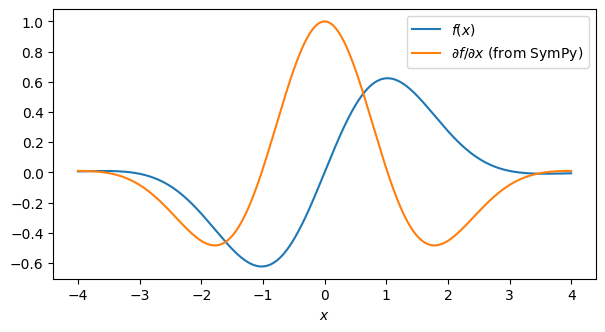

In [9]:
dfdx = sp.diff(f, x)                                 # symbolic derivative from 1.3
dfdx_num = sp.lambdify((x, a), dfdx, "numpy")        # a Python function of (x, a) using NumPy

xs = np.linspace(-4, 4, 400)
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.plot(xs, sp.lambdify((x, a), f, "numpy")(xs, 0.3), label="$f(x)$")
ax.plot(xs, dfdx_num(xs, 0.3), label=r"$\partial f/\partial x$ (from SymPy)")
ax.set_xlabel("$x$"); ax.legend(); plt.show()

<hr/>
## 2. Lagrangian mechanics in one paragraph

Describe the system with **generalised coordinates** $q_1,\dots,q_N$ that automatically respect the constraints (for a pendulum: angles, not Cartesian positions,
so the rod length is fixed by construction). Write the kinetic energy $T(q,\dot q)$ and the potential energy $V(q)$, and form the **Lagrangian**
$$L(q,\dot q) = T(q,\dot q) - V(q).$$
The motion satisfies the **Euler–Lagrange equations**, one per coordinate:
$$\frac{d}{dt}\frac{\partial L}{\partial \dot q_i} - \frac{\partial L}{\partial q_i} = 0,\qquad i = 1,\dots,N.$$
For a time-independent $L$ whose kinetic energy is a homogeneous quadratic function of the velocities $\dot q$ (no linear terms) (true for all systems in this notebook), the energy $E = T + V$ is conserved.
We use this as a check of every simulation.

**Reading the partial derivatives.** In $\partial L/\partial q_i$ and $\partial L/\partial\dot q_i$ the coordinates and the velocities are treated as
independent variables: $L$ is an ordinary function of $2N$ numbers, and each derivative is taken with the other $2N-1$ held fixed. Only afterwards,
in $\frac{d}{dt}$, are $q(t)$ and $\dot q(t)$ the functions of time along the motion. A check with one particle on a line, $L = \tfrac12 m\dot x^2 - V(x)$:
$\partial L/\partial\dot x = m\dot x$ (the momentum), $\frac{d}{dt}(m\dot x) = m\ddot x$, and $\partial L/\partial x = -V'(x)$, so the Euler–Lagrange equation is
$m\ddot x = -V'(x)$, Newton's second law. The advantage of the Lagrangian form appears with constraints: in angle coordinates the forces of the rods
never have to be computed.

<hr/>
## 3. The single pendulum

A mass $m$ on a massless rod of length $l$; the angle $\theta$ is measured from the downward vertical. The position of the mass is
$x = l\sin\theta$, $y = -l\cos\theta$. We let SymPy do every step.

In [10]:
t = sp.symbols("t", real=True)
m, l, g = sp.symbols("m l g", positive=True)
theta = sp.Function("theta")(t)

# Cartesian position of the mass, expressed through the generalised coordinate theta(t)
x_pos = l * sp.sin(theta)
y_pos = -l * sp.cos(theta)

# Kinetic and potential energy. sp.Rational(1, 2) is the exact fraction 1/2; writing 0.5 would put a
# floating-point number into the formula, and SymPy would then print and simplify it with decimals.
T = sp.Rational(1, 2) * m * (sp.diff(x_pos, t)**2 + sp.diff(y_pos, t)**2)
V = m * g * y_pos
L = sp.simplify(T - V)
show(r"T = ", sp.simplify(T), r",\qquad V = ", V)
show(r"L = ", L)

<IPython.core.display.Math object>

<IPython.core.display.Math object>

The Euler–Lagrange equation for $\theta$, and its solution for $\ddot\theta$:

In [11]:
theta_dot = sp.diff(theta, t)

# Euler-Lagrange equation:  d/dt (dL/d theta_dot) - dL/d theta = 0
EL = sp.diff(sp.diff(L, theta_dot), t) - sp.diff(L, theta)
show(r"\frac{d}{dt}\frac{\partial L}{\partial\dot\theta} - \frac{\partial L}{\partial\theta} = ", sp.simplify(EL), " = 0")

# Solve for the angular acceleration. sp.solve returns a list of solutions; the equation is linear in
# theta'' and has exactly one, which [0] takes out of the list.
theta_ddot = sp.solve(EL, sp.diff(theta, t, 2))[0]
show(r"\ddot\theta = ", theta_ddot)

<IPython.core.display.Math object>

<IPython.core.display.Math object>

For small angles $\sin\theta\approx\theta$ and the equation becomes the harmonic oscillator with $\omega_0 = \sqrt{g/l}$. SymPy can check this and solve it.
`sp.series` expands in a symbol, not in a function such as $\theta(t)$, so $\theta(t)$ is first replaced by a plain symbol $\vartheta$, expanded to first order,
and substituted back; `.removeO()` deletes the remainder term $O(\vartheta^2)$, leaving an ordinary expression.
`sp.dsolve` returns an equation $\theta(t) = \dots$; `.rhs` (right-hand side) takes the expression after the equals sign. $C_1$ and $C_2$ in the result are the
two integration constants of a second-order equation, fixed by the initial angle and angular velocity.

In [12]:
small = sp.series(theta_ddot.subs(theta, sp.Symbol("vartheta")), sp.Symbol("vartheta"), 0, 2).removeO()
show(r"\ddot\theta \approx ", small.subs(sp.Symbol("vartheta"), theta))
show(r"\theta(t) = ", sp.dsolve(sp.Eq(sp.diff(theta, t, 2), small.subs(sp.Symbol("vartheta"), theta))).rhs)

<IPython.core.display.Math object>

<IPython.core.display.Math object>

### 3.1 Phase portrait
The state of the pendulum is the point $(\theta, \dot\theta)$ in **phase space**. Since the energy
$E(\theta,\dot\theta) = \tfrac12 m l^2\dot\theta^2 - m g l\cos\theta$ is conserved, every trajectory lies on a contour line of $E$.
We plot these contours with the energy from SymPy (`lambdify`), with $m = l = 1$, $g = 9.81$.

Two technical steps in the code: for clarity we first replace $\dot\theta(t)$ by a plain symbol (its LaTeX name only changes how it is printed) and
$\theta(t)$ by the symbol `q` (`lambdify` could also take $\theta(t)$ and $\dot\theta(t)$ directly as arguments). `np.meshgrid` turns two 1D grids into two 2D arrays holding the
$\theta$ and $\dot\theta$ coordinates of every point of the plane; `contour` needs the function values on such a grid.

- $E < mgl$: closed curves around $(0,0)$ — **oscillations**;
- $E > mgl$: open curves — **rotations** (the pendulum goes over the top);
- $E = mgl$: the **separatrix**, which ends at the unstable equilibrium $\theta = \pm\pi$ (pendulum pointing up).

The picture repeats every $2\pi$ along the $\theta$ axis because $\theta$ and $\theta + 2\pi$ are the same position of the pendulum; the plotted range
$[-2\pi, 2\pi]$ shows two copies so that the rotations, which run from one copy into the next, are visible.

<IPython.core.display.Math object>

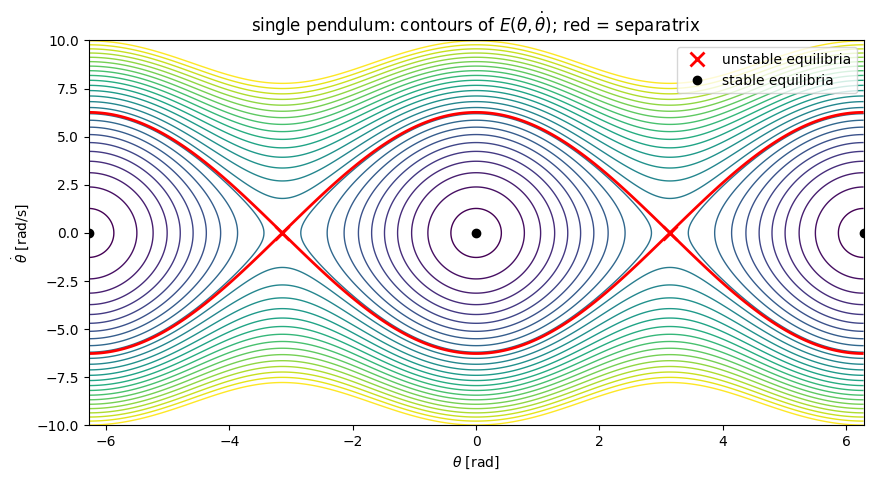

In [13]:
w = sp.symbols(r"\dot\theta")                                # a plain symbol standing for the angular velocity
E_expr = (T + V).subs(sp.diff(theta, t), w).subs(theta, sp.Symbol("q"))
E_num = sp.lambdify((sp.Symbol("q"), w, m, l, g), E_expr, "numpy")
show(r"E = ", sp.simplify(E_expr))

qq, ww = np.meshgrid(np.linspace(-2 * np.pi, 2 * np.pi, 500), np.linspace(-10, 10, 400))
EE = E_num(qq, ww, 1.0, 1.0, 9.81)

fig, ax = plt.subplots(figsize=(10, 5))
# the lowest energy is -m g l = -9.81 (at rest at the bottom); the 25 levels from -9 to 40 are a display choice
ax.contour(qq, ww, EE, levels=np.linspace(-9, 40, 25), cmap="viridis", linewidths=1)
ax.contour(qq, ww, EE, levels=[9.81], colors="red", linewidths=2)        # separatrix E = m g l
ax.plot([-np.pi, np.pi], [0, 0], "rx", ms=10, mew=2, label="unstable equilibria")
ax.plot([-2 * np.pi, 0, 2 * np.pi], [0, 0, 0], "ko", ms=6, label="stable equilibria")
ax.set_xlabel(r"$\theta$ [rad]"); ax.set_ylabel(r"$\dot\theta$ [rad/s]")
ax.set_title("single pendulum: contours of $E(\\theta,\\dot\\theta)$; red = separatrix")
ax.legend(loc="upper right"); plt.show()

<hr/>
## 4. The N-link pendulum with SymPy

### 4.1 Geometry
Masses $m_1,\dots,m_N$ sit at the ends of massless rods of lengths $l_1,\dots,l_N$; rod 1 hangs from the fixed pivot at the origin.
Each angle $\theta_i$ is measured from the downward vertical. The position of mass $k$ is the sum of the rod vectors up to $k$:
$$x_k = \sum_{j=1}^{k} l_j\sin\theta_j,\qquad y_k = -\sum_{j=1}^{k} l_j\cos\theta_j .$$
Then
$$T = \frac12\sum_{k=1}^{N} m_k\big(\dot x_k^2 + \dot y_k^2\big),\qquad V = g\sum_{k=1}^{N} m_k\,y_k,\qquad L = T - V .$$

The next cell only draws the sketch below. `draw_chain` uses only basic Matplotlib plotting commands and does not need to be studied in detail;
the part that matters is the first two lines of the function, which are the formulas for $x_k$, $y_k$ above (`np.cumsum` gives the running sums).

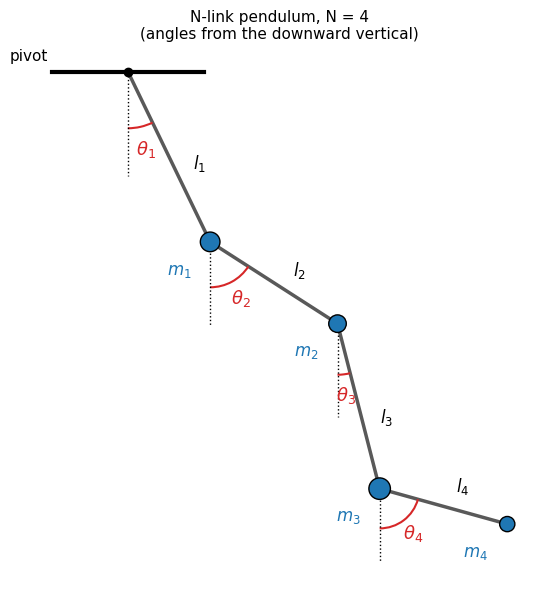

In [14]:
from matplotlib.patches import Arc

def draw_chain(ax, theta, lengths, masses=None, labels=True):
    # Draw an N-link pendulum with angles theta (from the downward vertical) and rod lengths.
    N = len(theta)
    xs = np.concatenate([[0.0], np.cumsum(lengths * np.sin(theta))])     # pivot + N masses
    ys = np.concatenate([[0.0], -np.cumsum(lengths * np.cos(theta))])
    ax.plot([-0.4, 0.4], [0, 0], color="k", lw=3)                           # ceiling
    ax.plot(xs, ys, "-", color="0.35", lw=2.5, zorder=1)                    # rods
    sizes = 120 * (np.ones(N) if masses is None else np.asarray(masses) / np.max(masses))
    ax.scatter(xs[1:], ys[1:], s=sizes * 2, color="C0", zorder=3, edgecolor="k")
    ax.plot(0, 0, "o", color="k", ms=6, zorder=4)                           # pivot
    if labels:
        for k in range(N):
            ax.plot([xs[k], xs[k]], [ys[k], ys[k] - 0.55 * lengths[k]], "k:", lw=1)       # vertical reference
            start, end = (-90, -90 + np.rad2deg(theta[k])) if theta[k] > 0 else (-90 + np.rad2deg(theta[k]), -90)
            ax.add_patch(Arc((xs[k], ys[k]), 0.6 * lengths[k], 0.6 * lengths[k], theta1=start, theta2=end, color="C3", lw=1.5))
            mid = np.deg2rad(-90) + theta[k] / 2
            ax.text(xs[k] + 0.42 * lengths[k] * np.cos(mid), ys[k] + 0.42 * lengths[k] * np.sin(mid),
                    rf"$\theta_{k+1}$", color="C3", fontsize=13, ha="center", va="center")
            # rod label: 60 % along the rod, shifted perpendicular to it, away from the angle arc
            normal = np.array([np.cos(theta[k]), np.sin(theta[k])])
            pos = np.array([xs[k], ys[k]]) + 0.6 * np.array([xs[k + 1] - xs[k], ys[k + 1] - ys[k]]) + 0.13 * normal
            ax.text(pos[0], pos[1], rf"$l_{k+1}$", fontsize=12, ha="center", va="center")
            # mass label: lower left of the mass (free of rods, arcs and the vertical reference line)
            ax.text(xs[k + 1] - 0.1, ys[k + 1] - 0.1, rf"$m_{k+1}$", fontsize=12, color="C0", ha="right", va="top")
    ax.set_aspect("equal"); ax.axis("off")

fig, ax = plt.subplots(figsize=(7, 7))
draw_chain(ax, theta=np.array([0.45, 1.0, 0.25, 1.3]), lengths=np.array([1.0, 0.8, 0.9, 0.7]), masses=[1.0, 0.8, 1.2, 0.6])
ax.text(-0.42, 0.06, "pivot", fontsize=11, ha="right")
ax.set_title("N-link pendulum, N = 4\n(angles from the downward vertical)", fontsize=11)
plt.show()

### 4.2 Deriving the equations for any N
The function below follows the recipe of Section 3 for arbitrary $N$. After forming the Euler–Lagrange expressions we replace
$\theta_i(t), \dot\theta_i, \ddot\theta_i$ by plain symbols $q_i, w_i, a_i$ (easier to handle). Each Euler–Lagrange equation is **linear** in the
accelerations $a_i = \ddot\theta_i$, so the system can be written as
$$M(q)\,\ddot q = F(q,\dot q),$$
with the **mass matrix** $M$ and a right-hand side $F$ (gravity and centrifugal terms). `sp.linear_eq_to_matrix` extracts $M$ and $F$.
$M$ is the matrix of second derivatives of $T$ with respect to the velocities, $M_{ij} = \partial^2 T/\partial\dot q_i\,\partial\dot q_j$, because $T$ is quadratic in $\dot q$.
It is therefore **symmetric**, and **positive definite**, since $T = \tfrac12\dot q^{\top} M\dot q > 0$ for every non-zero velocity. Hence $M$ is invertible, and the equations
can always be solved for the accelerations.

Two SymPy details used below. `sp.symbols("m1:4")` creates the numbered symbols `m1, m2, m3`; as in Python's `range`, the upper end is excluded, hence
`f"m1:{N + 1}"` for $N$ symbols. The substitutions must start with the **highest** derivative: $\ddot\theta_i$ is the derivative of $\dot\theta_i$, so if
$\dot\theta_i$ were replaced by the symbol $w_i$ first, $\ddot\theta_i$ would turn into the time derivative of a constant symbol, i.e. $0$, and the accelerations
would disappear from the equations.

In [15]:
def derive_n_pendulum(N):
    """Symbolic equations of motion M(q) a = F(q, w) of the N-link pendulum, and its energy."""
    t = sp.symbols("t", real=True)
    g = sp.symbols("g", positive=True)
    m = sp.symbols(f"m1:{N + 1}", positive=True)          # (m1, ..., mN)
    l = sp.symbols(f"l1:{N + 1}", positive=True)          # (l1, ..., lN)
    th = [sp.Function(f"theta{i + 1}")(t) for i in range(N)]

    # positions as running sums, kinetic and potential energy
    x_k, y_k, T, V = 0, 0, 0, 0
    for k in range(N):
        x_k += l[k] * sp.sin(th[k])
        y_k += -l[k] * sp.cos(th[k])
        T += sp.Rational(1, 2) * m[k] * (sp.diff(x_k, t)**2 + sp.diff(y_k, t)**2)
        V += m[k] * g * y_k
    L = T - V

    # Euler-Lagrange expressions  d/dt dL/d(theta_dot) - dL/d(theta),  one per coordinate
    EL = [sp.diff(sp.diff(L, sp.diff(th_i, t)), t) - sp.diff(L, th_i) for th_i in th]

    # replace theta_i'' -> a_i, theta_i' -> w_i, theta_i -> q_i  (order matters: highest derivative first, see above)
    q = sp.symbols(f"q1:{N + 1}"); w = sp.symbols(f"w1:{N + 1}"); a = sp.symbols(f"a1:{N + 1}")
    replace = {}
    for i in range(N):
        replace[sp.diff(th[i], t, 2)] = a[i]
    for i in range(N):
        replace[sp.diff(th[i], t)] = w[i]
    EL = [e.subs(replace).subs(dict(zip(th, q))) for e in EL]
    energy = (T + V).subs(replace).subs(dict(zip(th, q)))

    # EL_i = sum_j M_ij a_j - F_i = 0   ->   M a = F
    M, F = sp.linear_eq_to_matrix(EL, a)
    # M and F are simplified; L and the energy are returned unsimplified, because simplifying them is the
    # slowest step and the numerical functions built from them do not need it
    return dict(M=sp.simplify(M), F=sp.simplify(F), L=L.subs(replace).subs(dict(zip(th, q))),
                E=energy, q=q, w=w, m=m, l=l, g=g)

t_derive = {}                                         # derivation times, used again in the cost table below
t0 = time.perf_counter()
dp = derive_n_pendulum(2)
t_derive[2] = time.perf_counter() - t0
print(f"N = 2 derived in {t_derive[2]:.1f} s")
show(r"L = ", sp.simplify(dp["L"]))
show(r"M(q) = ", dp["M"])
show(r"F(q, w) = ", dp["F"])

N = 2 derived in 0.7 s


<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

Compare with the textbook double pendulum. Dividing the first row by $l_1$ and the second by $m_2 l_2$:
$$(m_1+m_2)\,l_1\ddot\theta_1 + m_2 l_2\cos(\theta_1-\theta_2)\,\ddot\theta_2 = -m_2 l_2\dot\theta_2^2\sin(\theta_1-\theta_2) - (m_1+m_2)\,g\sin\theta_1,$$
$$l_1\cos(\theta_1-\theta_2)\,\ddot\theta_1 + l_2\ddot\theta_2 = l_1\dot\theta_1^2\sin(\theta_1-\theta_2) - g\sin\theta_2 .$$
SymPy checks the agreement. In SymPy, `==` compares the *form* of two expressions, not their mathematical value: `sp.sin(x)**2 + sp.cos(x)**2 == 1` is
`False`. Two formulas are therefore compared by simplifying their difference and testing whether the result is the zero matrix.

In [16]:
q1, q2 = dp["q"]; w1, w2 = dp["w"]; m1, m2 = dp["m"]; l1, l2 = dp["l"]; g_ = dp["g"]
d = q1 - q2
M_book = sp.Matrix([[(m1 + m2) * l1, m2 * l2 * sp.cos(d)], [l1 * sp.cos(d), l2]])
F_book = sp.Matrix([-m2 * l2 * w2**2 * sp.sin(d) - (m1 + m2) * g_ * sp.sin(q1), l1 * w1**2 * sp.sin(d) - g_ * sp.sin(q2)])
scale = sp.diag(1 / l1, 1 / (m2 * l2))                       # row scaling described above
print("M agrees:", sp.simplify(scale * dp["M"] - M_book) == sp.zeros(2, 2))
print("F agrees:", sp.simplify(scale * dp["F"] - F_book) == sp.zeros(2, 1))

M agrees: True
F agrees: True


### 4.3 Structure of the mass matrix
For $N = 3$ the matrix shows a pattern:
$$M_{ij} = l_i\,l_j\cos(\theta_i - \theta_j)\sum_{k\ge\max(i,j)} m_k .$$
(Rod $i$ "carries" all masses below it.) We verify the formula for $N=3$ symbolically.

In [17]:
t0 = time.perf_counter()
tp = derive_n_pendulum(3)
t_derive[3] = time.perf_counter() - t0
print(f"N = 3 derived in {t_derive[3]:.1f} s")
show(r"M = ", tp["M"])

q, m_, l_ = tp["q"], tp["m"], tp["l"]
M_formula = sp.Matrix(3, 3, lambda i, j: l_[i] * l_[j] * sp.cos(q[i] - q[j]) * sum(m_[max(i, j):]))
print("formula agrees:", sp.simplify(tp["M"] - M_formula) == sp.zeros(3, 3))

N = 3 derived in 2.0 s


<IPython.core.display.Math object>

formula agrees: True


**Cost of the symbolic route.** The expressions grow quickly with $N$ and so does the time SymPy needs. `sp.count_ops` counts the arithmetic
operations in a formula, a simple measure of its size. The cases $N = 2, 3$ were derived and timed above, so only $N = 1$ is computed here.
To keep the notebook fast, $N = 4$ is left out; adding `4` to the list shows the next step (on our machine about three times the time for $N = 3$).

In [18]:
results = {2: dp, 3: tp}
for N in [1, 2, 3]:
    if N not in results:                                 # N = 2 and N = 3 are already available
        t0 = time.perf_counter()
        results[N] = derive_n_pendulum(N)
        t_derive[N] = time.perf_counter() - t0
    print(f"N = {N}: {t_derive[N]:5.1f} s,  number of operations in F: {sp.count_ops(results[N]['F'])}")

N = 1:   0.1 s,  number of operations in F: 5
N = 2:   0.7 s,  number of operations in F: 26
N = 3:   2.0 s,  number of operations in F: 79


### 4.4 From SymPy to a numerical acceleration function
We turn $M$ and $F$ into NumPy functions with `lambdify` and solve $M\ddot q = F$ numerically. The function accepts either one state
(arrays of shape `(N,)`) or a batch of states (shape `(N, B)`) — we will need batches for the Poincaré sections.

How the matrix is assembled and solved:
- Iterating over a SymPy matrix gives its entries row by row ($M_{11}, M_{12}, \dots, M_{1N}, M_{21}, \dots$), so the flat list of evaluated entries is reshaped
  to `(N, N, *shape)`; `*shape` appends the batch shape, which is empty for a single state.
- `np.linalg.solve(M, F)` solves the linear system $M a = F$. It is cheaper and more accurate than computing the inverse $M^{-1}$ and multiplying, and $M$
  (a mass matrix, positive definite) always has a unique solution. For a stack of systems, `solve` requires the matrix indices to be the **last two** axes,
  shape `(B, N, N)`, and the right-hand side to have shape `(B, N, 1)`. `np.moveaxis` moves the batch axis to the front, `[..., None]` appends an axis of
  length 1, and `[..., 0]` removes it again from the result.

In [19]:
def make_sympy_accel(res, m_vals, l_vals, g_val):
    """Return accel(q, w) = M(q)^{-1} F(q, w) for given numerical masses, lengths and g."""
    N = len(res["q"])
    # one dictionary {symbol: number}: ** unpacks the two dictionaries into the new one, and g is added as a third entry
    params = {**dict(zip(res["m"], m_vals)), **dict(zip(res["l"], l_vals)), res["g"]: g_val}
    # one NumPy function per matrix entry (entries that are constants, e.g. l1**2 (m1 + m2), return a plain number)
    M_funs = [sp.lambdify(res["q"], e, "numpy") for e in res["M"].subs(params)]
    F_funs = [sp.lambdify(res["q"] + res["w"], e, "numpy") for e in res["F"].subs(params)]
    E_fun = sp.lambdify(res["q"] + res["w"], res["E"].subs(params), "numpy")

    def evaluate(funs, args, shape):
        # evaluate all entries and broadcast constant entries to the batch shape
        return np.array([np.broadcast_to(np.asarray(f(*args), dtype=float), shape) for f in funs])

    def accel(q, w):
        shape = np.shape(q[0])                                   # () for one state, (B,) for a batch
        M = evaluate(M_funs, q, shape).reshape(N, N, *shape)
        F = evaluate(F_funs, list(q) + list(w), shape).reshape(N, *shape)
        # move the batch axis to the front for np.linalg.solve, then back
        M = np.moveaxis(M, (0, 1), (-2, -1)); F = np.moveaxis(F, 0, -1)[..., None]
        return np.moveaxis(np.linalg.solve(M, F)[..., 0], -1, 0)

    def energy(q, w):
        return E_fun(*q, *w)
    return accel, energy

# double pendulum with m = l = 1, g = 9.81
accel_dp, energy_dp = make_sympy_accel(dp, [1.0, 1.0], [1.0, 1.0], 9.81)
print("one state :", accel_dp(np.array([0.3, -0.2]), np.array([0.1, 0.5])))
print("batch of 3:", accel_dp(np.array([[0.3, 1.0, 2.0], [-0.2, 0.0, 0.5]]), np.zeros((2, 3))).shape)

one state : [-6.20607269  7.40008156]
batch of 3: (2, 3)


<hr/>
## 5. The N-link pendulum with automatic differentiation

In this approach no equations of motion are derived. We only need $L(q,\dot q)$ as a function that computes a number. Expanding the time derivative in the
Euler–Lagrange equation with the chain rule,
$$\frac{d}{dt}\frac{\partial L}{\partial\dot q_i} = \sum_j \frac{\partial^2 L}{\partial\dot q_i\,\partial\dot q_j}\,\ddot q_j + \sum_j\frac{\partial^2 L}{\partial\dot q_i\,\partial q_j}\,\dot q_j ,$$
so the Euler–Lagrange equations become
$$\underbrace{\Big[\frac{\partial^2 L}{\partial\dot q\,\partial\dot q}\Big]}_{M}\ddot q = \frac{\partial L}{\partial q} - \Big[\frac{\partial^2 L}{\partial\dot q\,\partial q}\Big]\dot q
\qquad\Longrightarrow\qquad
\ddot q = M^{-1}\Big(\nabla_q L - \big(\nabla_q\nabla_{\dot q}L\big)\,\dot q\Big).$$
Here $\big(\nabla_q\nabla_{\dot q}L\big)$ is the matrix with elements $C_{ij} = \partial^2 L/\partial\dot q_i\,\partial q_j$, so that $(C\dot q)_i = \sum_j C_{ij}\dot q_j$.
Everything on the right is a derivative of the scalar function $L$, which autodiff computes exactly up to rounding errors:
- `grad(L, argnums=0)` — the gradient $\nabla_q L$. `grad` does not return a number: it returns a **new Python function** which, called with
  `(q, qd)`, returns $\partial L/\partial q$. `argnums` selects the argument with respect to which the derivative is taken (0 = `q`, 1 = `qd`);
- `hessian(L, argnums=1)` — the matrix $M = \partial^2 L/\partial\dot q\,\partial\dot q$, again as a function of `(q, qd)`;
- the product $\big(\nabla_q\nabla_{\dot q}L\big)\dot q$ is a *Jacobian-vector product* of the function $q\mapsto\nabla_{\dot q}L(q,\dot q)$ with the vector $\dot q$: `jvp` computes it
  without building the full matrix. `jvp(f, (x,), (v,))` returns two results, $f(x)$ and the directional derivative $J_f(x)\,v$; only the second is needed,
  so the first is assigned to `_` (a name conventionally used for a discarded value). The `lambda` fixes `qd`, so that the function given to `jvp` depends
  on `q` only;
- `torch.linalg.solve(M, b)` solves $M\ddot q = b$ without forming $M^{-1}$, as `np.linalg.solve` in Section 4.4.

`torch.func` provides these operations as functions that transform functions (like in the mathematical notation).

The Lagrangian of the chain, written with `cumsum` (the velocities follow from differentiating the running sums of Section 4.1):
$$\dot x_k = \sum_{j\le k} l_j\cos\theta_j\,\dot\theta_j,\qquad \dot y_k = \sum_{j\le k} l_j\sin\theta_j\,\dot\theta_j .$$

In [20]:
def lagrangian_chain(q, qd, m, l, g):
    """L = T - V of the N-link pendulum; m, l have length N; q, qd have shape (N,), or (B, N) for B chains."""
    vx = torch.cumsum(l * torch.cos(q) * qd, dim=-1)        # dim=-1: sums run over the last axis (the links)
    vy = torch.cumsum(l * torch.sin(q) * qd, dim=-1)
    T = 0.5 * torch.sum(m * (vx**2 + vy**2), dim=-1)
    y = -torch.cumsum(l * torch.cos(q), dim=-1)
    V = g * torch.sum(m * y, dim=-1)
    return T - V

def energy_chain(q, qd, m, l, g):
    vx = torch.cumsum(l * torch.cos(q) * qd, dim=-1)
    vy = torch.cumsum(l * torch.sin(q) * qd, dim=-1)
    y = -torch.cumsum(l * torch.cos(q), dim=-1)
    return 0.5 * torch.sum(m * (vx**2 + vy**2), dim=-1) + g * torch.sum(m * y, dim=-1)

def accel_from_lagrangian(L, q, qd):
    """Accelerations q_ddot from the Euler-Lagrange equations of ANY Lagrangian L(q, qd), by autodiff."""
    dL_dq = grad(L, argnums=0)(q, qd)                       # nabla_q L
    M = hessian(L, argnums=1)(q, qd)                        # d^2 L / d qd d qd
    dL_dqd = lambda qq: grad(L, argnums=1)(qq, qd)          # q -> nabla_qd L(q, qd)
    _, C_qd = jvp(dL_dqd, (q,), (qd,))                      # (d^2 L / d qd d q) @ qd
    return torch.linalg.solve(M, dL_dq - C_qd)

**Check against SymPy.** We draw random states (angles and angular velocities) and deliberately *unequal* masses and lengths,
so that an error cannot cancel by symmetry, and compare the accelerations from both routes for $N = 2$ and $N = 3$.

In [21]:
rng = np.random.default_rng(0)
for res, N in [(dp, 2), (tp, 3)]:
    m_vals, l_vals = np.array([1.7, 0.9, 1.3])[:N], np.array([1.3, 0.6, 0.8])[:N]
    accel_sym, _ = make_sympy_accel(res, m_vals, l_vals, 9.81)
    m_t, l_t = torch.tensor(m_vals), torch.tensor(l_vals)
    L = lambda q, qd: lagrangian_chain(q, qd, m_t, l_t, 9.81)

    max_diff = 0.0
    for _ in range(100):
        q = rng.uniform(-np.pi, np.pi, N); w = rng.uniform(-8, 8, N)
        a_sym = accel_sym(q, w)
        a_ad = accel_from_lagrangian(L, torch.tensor(q), torch.tensor(w)).numpy()
        max_diff = max(max_diff, np.max(np.abs(a_sym - a_ad)))
    print(f"N = {N}: max |a_SymPy - a_autodiff| over 100 random states = {max_diff:.1e}")

N = 2: max |a_SymPy - a_autodiff| over 100 random states = 9.9e-14


N = 3: max |a_SymPy - a_autodiff| over 100 random states = 1.1e-13


The angles cover a full period and the velocities $\pm 8$ rad/s, a range typical of the motions simulated later; 100 states are more than enough to
expose an error in a formula (500 states, tried when preparing the notebook, also agree to about $10^{-13}$ but take five times longer), and the exact numbers are arbitrary.
The two routes agree to about $10^{-13}$, i.e. to rounding error: the accelerations at these states reach up to about 170 rad/s$^2$, and float64 resolves relative
differences of about $10^{-16}$, so $10^{-13}$ is a relative difference of order $10^{-15}$, a few rounding steps. The autodiff route needed only the few lines of `lagrangian_chain`, works for any $N$
without new derivations, and for any other Lagrangian (Exercise 4).

The price: every call performs several automatic-differentiation passes, so it is slower than evaluating the formulas from `lambdify` (measured below).
The first call of a function includes one-time set-up work and is slower than the following ones, so every time is an average over repeated calls after
one warm-up call; the numbers of repetitions are arbitrary.
As a rule, the symbolic route is preferable when the formulas are manageable and speed matters, autodiff when the model is large, changes often, or
when $L$ is itself learned (Lagrangian neural networks).

In [22]:
m_t, l_t = torch.ones(10), torch.ones(10)
L10 = lambda q, qd: lagrangian_chain(q, qd, m_t, l_t, 9.81)
q, qd = torch.rand(10), torch.rand(10)
accel_from_lagrangian(L10, q, qd)                    # warm-up call, not timed
t0 = time.perf_counter()
for _ in range(20):
    a10 = accel_from_lagrangian(L10, q, qd)
print(f"N = 10 by autodiff: {1e3 * (time.perf_counter() - t0) / 20:.1f} ms per acceleration")
# (the SymPy derivation time in Section 4.3 grows by a factor of about 3 per additional link from N = 2 on; N = 10 is not attempted)

# cost of one acceleration evaluation for N = 2: lambdify formulas vs autodiff
q2, w2 = np.array([0.3, -0.2]), np.array([0.1, 0.5])
L2_chain = lambda q, qd: lagrangian_chain(q, qd, torch.ones(2), torch.ones(2), 9.81)
accel_dp(q2, w2); accel_from_lagrangian(L2_chain, torch.tensor(q2), torch.tensor(w2))     # warm-up calls
t0 = time.perf_counter()
for _ in range(200):
    accel_dp(q2, w2)
t_sym = (time.perf_counter() - t0) / 200
t0 = time.perf_counter()
for _ in range(50):
    accel_from_lagrangian(L2_chain, torch.tensor(q2), torch.tensor(w2))
t_ad = (time.perf_counter() - t0) / 50
print(f"one acceleration, N = 2:  lambdify {1e6 * t_sym:.0f} microseconds,  autodiff {1e6 * t_ad:.0f} microseconds")

N = 10 by autodiff: 7.7 ms per acceleration


one acceleration, N = 2:  lambdify 57 microseconds,  autodiff 7926 microseconds


Reading the printed times (they depend on the computer): for $N = 2$ the autodiff acceleration is about two orders of magnitude slower than the
`lambdify` formulas. The autodiff time for $N = 10$ is about the same as for $N = 2$: at these sizes the cost is dominated by the fixed overhead of the
`torch.func` calls, not by the arithmetic (in our tests the time per call stayed of order 10 ms, about 8 ms in the run above, from $N = 2$ to $N = 20$). Section 9 shows how this
overhead is reduced for long simulations.

<hr/>
## 6. Integrating the equations of motion

Integration methods are formulated for **first-order** equations $\dot s = f(s)$. A second-order equation is brought into this form by treating the
velocity $w = \dot q$ as an additional unknown; the equations of motion then form a first-order system for the state $s = (q, \dot q)$:
$$\frac{d}{dt}\begin{pmatrix} q\\ \dot q\end{pmatrix} = \begin{pmatrix}\dot q \\ \ddot q(q,\dot q)\end{pmatrix}.$$
We integrate it with the classical **4th-order Runge–Kutta** method (RK4): with time step $\Delta t$,
$$k_1 = f(s),\; k_2 = f(s + \tfrac{\Delta t}{2}k_1),\; k_3 = f(s + \tfrac{\Delta t}{2}k_2),\; k_4 = f(s + \Delta t\,k_3),\qquad
s \leftarrow s + \tfrac{\Delta t}{6}(k_1 + 2k_2 + 2k_3 + k_4).$$
The error after a fixed time is proportional to $\Delta t^4$.
The four $k$'s are estimates of the slope $ds/dt$: at the start of the step ($k_1$), twice at the midpoint ($k_2$, $k_3$, each using the previous estimate to
get there) and at the end ($k_4$). The step uses their weighted average, like Simpson's rule for an integral.

Why RK4: it is the standard general-purpose method for such systems. Each step needs four evaluations of the acceleration, and halving $\Delta t$ reduces the
error 16 times, whereas for the simplest (Euler) method, $s \leftarrow s + \Delta t\, f(s)$, the error is proportional to $\Delta t$ and halving the step only
halves it. RK4 does not conserve energy exactly; the energy slowly drifts, and Section 6.2 uses this drift to measure the accuracy. A derivation of the
formulas is found in numerical-analysis textbooks, e.g. W. H. Press *et al.*, *Numerical Recipes* (3rd ed.), Ch. 17.

In `simulate`, the number of steps is `int(round(T / dt))`. In floating-point arithmetic a quotient can come out slightly too small, e.g. `0.3 / 0.1`
gives `2.9999999999999996`, and `int` cuts off the fractional part (giving 2); rounding first gives the intended number.

Both functions also work for a **batch**: with `q` and `w` of shape `(N, B)`, the `B` columns are independent pendulums that are advanced together.
Most of the time of one step is fixed overhead (Python calls, building small arrays), so a batch of several trajectories costs little more than a single
one. The notebook uses this throughout to stay fast enough for the free Colab CPU.

`simulate` stores the state after every step in a list and converts the list with `np.array` at the end; time is the first axis, so `Q` has shape
`(n_steps + 1, N)` for one pendulum and `(n_steps + 1, N, B)` for a batch.

In [23]:
def rk4_step(accel, q, w, dt):
    """One RK4 step for q'' = accel(q, q'). Works for single states and batches."""
    k1q, k1w = w, accel(q, w)
    k2q, k2w = w + 0.5 * dt * k1w, accel(q + 0.5 * dt * k1q, w + 0.5 * dt * k1w)
    k3q, k3w = w + 0.5 * dt * k2w, accel(q + 0.5 * dt * k2q, w + 0.5 * dt * k2w)
    k4q, k4w = w + dt * k3w, accel(q + dt * k3q, w + dt * k3w)
    q_new = q + dt / 6 * (k1q + 2 * k2q + 2 * k3q + k4q)
    w_new = w + dt / 6 * (k1w + 2 * k2w + 2 * k3w + k4w)
    return q_new, w_new

def simulate(accel, q0, w0, T, dt):
    """Integrate from (q0, w0) up to time T; return times and arrays of q and w (time along axis 0)."""
    n_steps = int(round(T / dt))
    q, w = np.array(q0, float), np.array(w0, float)
    Q, W = [q], [w]
    for _ in range(n_steps):
        q, w = rk4_step(accel, q, w, dt)
        Q.append(q); W.append(w)
    return np.arange(n_steps + 1) * dt, np.array(Q), np.array(W)

### 6.1 A double-pendulum trajectory
Released from rest at $\theta_1 = 120^\circ$, $\theta_2 = -10^\circ$ ($m = l = 1$, $g = 9.81$).

**Choice of $\Delta t$ and $T$.** The natural time scale of a pendulum is $\sqrt{l/g} \approx 0.32$ s; the two small-oscillation periods of the double pendulum
are $2.6$ s and $1.1$ s (Exercise 2). A step $\Delta t = 2\cdot10^{-3}$ s resolves these scales with hundreds of steps. Measured for this trajectory over 10 s, the
largest relative energy error is $1.4\cdot10^{-7}$ for $\Delta t = 10^{-3}$ s, $2\cdot10^{-6}$ for $2\cdot10^{-3}$ s and $3\cdot10^{-5}$ for $4\cdot10^{-3}$ s,
so any of these steps gives the same plots. $T = 10$ s covers about four periods of the slower oscillation; it is kept short for speed, and $T = 30$ s
shows more of the irregular motion. (The energy at the start is $E(0) \approx 0.15$ J, i.e. $\approx 0.015\,mgl$, just above the energy $E = 0$ of both rods horizontal.)

Left: both angles as functions of time. Right: the paths of the two masses in the plane; mass 1 always stays on the circle of radius $l_1 = 1$ around
the pivot (the rod is rigid), while mass 2 can reach any point within distance $l_1 + l_2 = 2$.

relative energy drift over 10 s: 2.1e-06


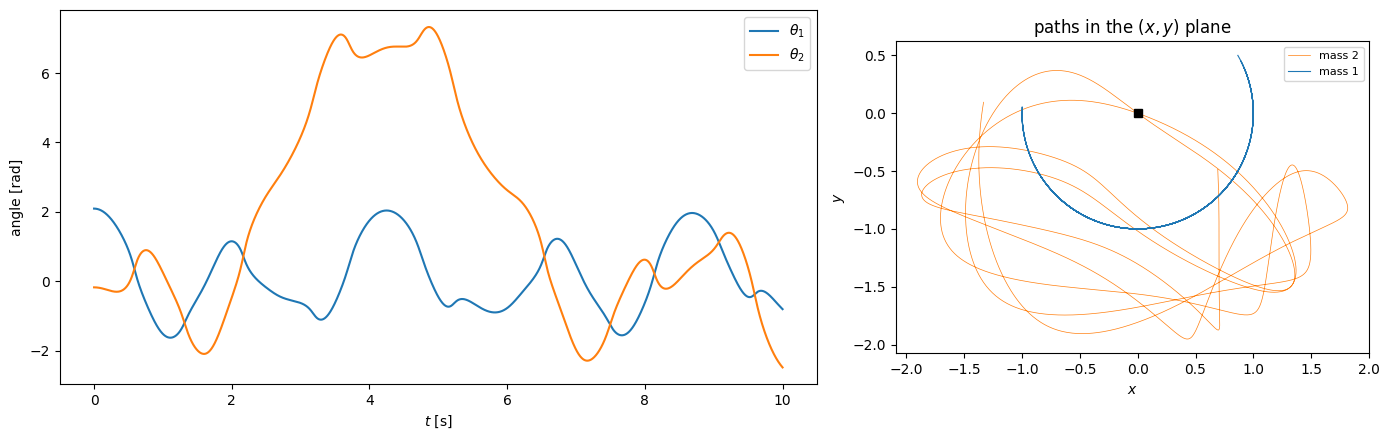

In [24]:
t_arr, Q, W = simulate(accel_dp, [np.deg2rad(120), np.deg2rad(-10)], [0.0, 0.0], T=10.0, dt=2e-3)
E = energy_dp(Q.T, W.T)
print(f"relative energy drift over 10 s: {np.max(np.abs(E - E[0])) / abs(E[0]):.1e}")

# Cartesian positions of both masses for the trajectory plot
x1, y1 = np.sin(Q[:, 0]), -np.cos(Q[:, 0])
x2, y2 = x1 + np.sin(Q[:, 1]), y1 - np.cos(Q[:, 1])

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5), gridspec_kw={"width_ratios": [1.6, 1]})
axes[0].plot(t_arr, Q[:, 0], label=r"$\theta_1$"); axes[0].plot(t_arr, Q[:, 1], label=r"$\theta_2$")
axes[0].set_xlabel("$t$ [s]"); axes[0].set_ylabel("angle [rad]"); axes[0].legend()
axes[1].plot(x2, y2, lw=0.5, color="C1", label="mass 2")
axes[1].plot(x1, y1, lw=0.8, color="C0", label="mass 1")
axes[1].plot(0, 0, "ks"); axes[1].set_aspect("equal"); axes[1].legend(loc="upper right", fontsize=8)
axes[1].set_title("paths in the $(x, y)$ plane"); axes[1].set_xlabel("$x$"); axes[1].set_ylabel("$y$")
fig.tight_layout(); plt.show()

### 6.2 Energy conservation as a test of the integrator
The exact motion conserves $E$; the numerical one does not, and the drift tells us how accurate the integration is.
For RK4 the error should scale as $\Delta t^4$ — a slope of 4 on a log-log plot.

The step is halved from $0.04$ s to $0.0025$ s, which gives equally spaced points on the logarithmic axis; $T = 3$ s keeps the cell fast. The dashed line
only shows the slope 4; it is drawn through the last point, and its vertical position has no other meaning. The asymptotic law $\propto\Delta t^4$ holds only
when $\Delta t$ is small enough: between the two largest steps the error falls about 28 times (slope $\approx 4.8$; at $\Delta t = 0.04$ s the energy error is
$0.14$, not small), between the two smallest about 15 times (slope $\approx 3.9$).

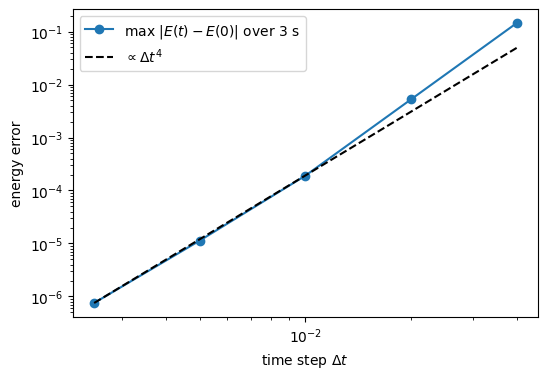

In [25]:
dts = [0.04, 0.02, 0.01, 0.005, 0.0025]
drifts = []
for dt in dts:
    _, Qd_, Wd_ = simulate(accel_dp, [np.deg2rad(120), np.deg2rad(-10)], [0.0, 0.0], T=3.0, dt=dt)
    Ed = energy_dp(Qd_.T, Wd_.T)
    drifts.append(np.max(np.abs(Ed - Ed[0])))

fig, ax = plt.subplots(figsize=(6, 4))
ax.loglog(dts, drifts, "o-", label="max $|E(t) - E(0)|$ over 3 s")
ax.loglog(dts, drifts[-1] * (np.array(dts) / dts[-1])**4, "k--", label=r"$\propto \Delta t^4$")
ax.set_xlabel(r"time step $\Delta t$"); ax.set_ylabel("energy error"); ax.legend()
plt.show()

### 6.3 Animation: small, large and very large amplitudes
Equal masses and lengths ($m_1 = m_2 = 1$, $l_1 = l_2 = 1$), released from rest with $\theta_1 = \theta_2 = \alpha$ for
$\alpha = 10^\circ$, $90^\circ$ and $170^\circ$. In every panel a second pendulum (drawn in a paler colour) starts with $\theta_1$ larger by $10^{-3}$ rad;
the line behind the lower mass shows its recent path.

`matplotlib.animation.FuncAnimation` calls a function `update(frame)` for every frame, and `to_jshtml()` turns the result into an
interactive player (play, pause, step) that works in Colab and Jupyter. The time needed is printed below the player.

Choices in the code, all of them for display only:
- all six pendulums are integrated as one batch, with $\Delta t = 4\cdot10^{-3}$ s (energy error $3\cdot10^{-5}$, Section 6.1); only every 30th state is
  drawn: one frame every $0.12$ s, about 8 frames per second. The frame rate and the resolution (`dpi=50`) are kept low so that the notebook file stays
  small; `frame_dt = 0.04` (a multiple of the integration step) and `dpi=100` give a smoother, sharper animation at several times the file size;
- the shift of $10^{-3}$ rad of the twin is chosen so that the separation becomes visible within the simulated 12 s; the trail shows the last 17 frames (about 2 s at `frame_dt = 0.12`; the number of frames is fixed, so a smaller `frame_dt` shortens the trail);
  "separated" means that the lower masses are more than $0.1\,l$ apart; all these values are arbitrary;
- `animation.embed_limit` raises matplotlib's default limit (20 MB) on the size of an animation stored inside the notebook;
- `blit=True` makes matplotlib redraw only the objects returned by `update` in each frame (faster), which is why `update` returns them;
  `default_mode="once"` makes the player stop at the end instead of looping.

In [26]:
from matplotlib import animation
from IPython.display import HTML
plt.rcParams["animation.embed_limit"] = 50          # allow animations up to 50 MB inside the notebook

t_start_anim = time.perf_counter()
amplitudes = [10, 90, 170]                           # initial angles in degrees
T_anim, dt_sim, frame_dt = 12.0, 4e-3, 0.12          # simulated time, integration step, time between frames
every = int(round(frame_dt / dt_sim))                # keep every 30th integration step

# 6 pendulums in one batch (columns): for every amplitude the reference and the 'twin' with theta1 + 1e-3 rad
q0 = np.deg2rad(np.vstack([np.repeat(amplitudes, 2), np.repeat(amplitudes, 2)])).astype(float)   # shape (2, 6)
q0[0, 1::2] += 1e-3                                  # columns 1, 3, 5 are the twins
_, Qa, _ = simulate(accel_dp, q0, np.zeros_like(q0), T=T_anim, dt=dt_sim)        # Qa: (steps, 2, 6)
Qa = Qa[::every]                                     # angles at the frame times
runs = []
for j in range(6):
    x1, y1 = np.sin(Qa[:, 0, j]), -np.cos(Qa[:, 0, j])                 # l1 = l2 = 1
    x2, y2 = x1 + np.sin(Qa[:, 1, j]), y1 - np.cos(Qa[:, 1, j])
    runs.append((x1, y1, x2, y2))
n_frames = len(runs[0][0])

# when do the lower masses of reference and twin first differ by more than 0.1 (in units of l)?
for k, a in enumerate(amplitudes):
    x2r, y2r, x2t, y2t = runs[2 * k][2], runs[2 * k][3], runs[2 * k + 1][2], runs[2 * k + 1][3]
    far = np.hypot(x2r - x2t, y2r - y2t) > 0.1
    print(f"alpha = {a:3d} deg: " + (f"twins separate at t = {np.argmax(far) * frame_dt:.1f} s" if far.any()
                                     else f"twins stay together for the whole {T_anim:.0f} s"))

fig, axes = plt.subplots(1, 3, figsize=(9.5, 3.6), dpi=50)
fig.subplots_adjust(left=0.01, right=0.99, bottom=0.09, top=0.92, wspace=0.05)     # narrow margins: small frames
artists = []
for k, ax in enumerate(axes):
    ax.set_xlim(-2.2, 2.2); ax.set_ylim(-2.2, 2.2); ax.set_aspect("equal")
    ax.set_xticks([]); ax.set_yticks([])
    ax.set_title(rf"$\theta_1 = \theta_2 = {amplitudes[k]}^\circ$ at $t = 0$")
    ax.plot(0, 0, "ks", ms=6)
    rod_ref, = ax.plot([], [], "o-", color="C0", lw=2.5, ms=8)              # reference pendulum
    rod_twin, = ax.plot([], [], "o-", color="C3", lw=1.5, ms=6, alpha=0.5)  # twin, shifted by 1e-3 rad
    trail, = ax.plot([], [], "-", color="C0", lw=0.8, alpha=0.5)
    artists.append((rod_ref, rod_twin, trail))
# the time label belongs to the middle axes (a figure-level text is not redrawn in the frames of a blitted animation)
time_text = axes[1].text(0.5, -0.05, "", transform=axes[1].transAxes, ha="center", va="top", fontsize=12)

def update(i):
    for k, (rod_ref, rod_twin, trail) in enumerate(artists):
        x1, y1, x2, y2 = runs[2 * k]                 # reference run of amplitude k
        u1, v1, u2, v2 = runs[2 * k + 1]             # twin run of amplitude k
        rod_ref.set_data([0, x1[i], x2[i]], [0, y1[i], y2[i]])
        rod_twin.set_data([0, u1[i], u2[i]], [0, v1[i], v2[i]])
        start = max(0, i - 17)                       # trail: the last 17 frames (about 2 s at frame_dt = 0.12)
        trail.set_data(x2[start:i + 1], y2[start:i + 1])
    time_text.set_text(f"t = {i * frame_dt:.2f} s")
    return [a for trio in artists for a in trio] + [time_text]

anim = animation.FuncAnimation(fig, update, frames=n_frames, interval=1000 * frame_dt, blit=True)
plt.close(fig)                                       # show only the animation player, not a static copy
player = HTML(anim.to_jshtml(default_mode="once"))
print(f"simulation and frames: {time.perf_counter() - t_start_anim:.0f} s")
player

alpha =  10 deg: twins stay together for the whole 12 s
alpha =  90 deg: twins separate at t = 10.7 s
alpha = 170 deg: twins separate at t = 2.3 s


simulation and frames: 3 s


At $10^\circ$ the motion is a regular superposition of the two normal modes (motions in which both angles oscillate with one common frequency and a fixed
ratio of amplitudes; Exercise 2 computes them), and the twin stays on top of the reference pendulum.
At $90^\circ$ the motion is irregular and the twin separates after about ten seconds. At $170^\circ$ the pendulum starts near the unstable upright position
and the two copies separate after about two seconds (the exact times are printed above the animation).

<hr/>
## 7. Chaos: sensitivity to initial conditions

Two double pendulums released from angles differing by $10^{-9}$ rad. We follow the distance between them in phase space,
$d(t) = \|s_A(t) - s_B(t)\|$. In a chaotic system it grows on average exponentially, $d(t)\sim d(0)\,e^{\lambda t}$, until it reaches the size of the
accessible phase space. $\lambda$ is the (largest) **Lyapunov exponent**. On a logarithmic vertical axis, as in the right panel below, exponential growth
appears as a straight line: $\ln d(t) = \ln d(0) + \lambda t$, with slope $\lambda$.

Choices in the code:
- The perturbation $10^{-9}$ rad is very small, so that the exponential phase lasts long before the distance saturates; any value well above the rounding
  level $10^{-16}$ would do. (The shifts of $10^{-3}$ rad in Section 6.3 and $10^{-4}$ rad in Section 9 were instead chosen so that the separation becomes
  visible within the simulated time.)
- The distance $d$ adds angles (rad) and angular velocities (rad/s), quantities with different units. This is acceptable: changing the weights of the
  coordinates in the distance changes only the prefactor of $d(t)$, not its exponential growth rate $\lambda$.
- $\lambda$ is the slope of $\ln d(t)$ versus $t$, obtained with `np.polyfit(t, ln d, 1)`, a least-squares fit of a straight line (polynomial of degree 1)
  that returns the slope and the intercept. The fit uses $1\,\mathrm{s} < t < 8\,\mathrm{s}$: at the start $d$ does not yet grow steadily
  (the perturbation first has to turn into the most unstable direction; here $d$ rises and falls again, staying of order $10^{-8}$, up to $t \approx 2$ s).
  The first second is left out; the remaining dip before $t = 2$ s barely affects the slope of a fit over seven seconds (starting the window at 2 s instead
  of 1 s changes $\lambda$ by about 2 %). The upper limit keeps the fit far from saturation, which sets in after about 20 s.
- Both pendulums are integrated as one batch (two columns) with $\Delta t = 5\cdot10^{-3}$ s for 25 s. With $\Delta t = 10^{-3}$ s the separation time and
  $\lambda$ change by less than 1 %.

theta2 of A and B first differ by more than 0.1 rad at t = 19.2 s


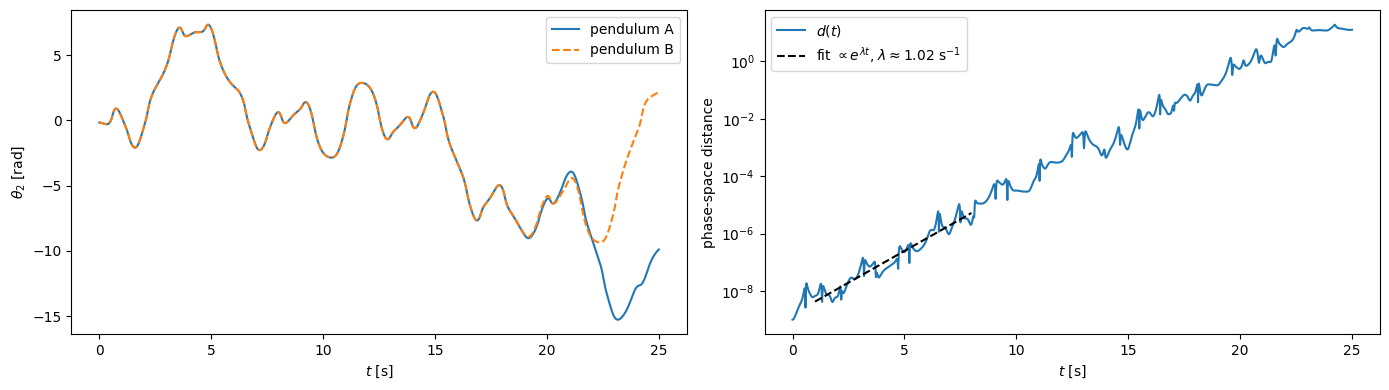

In [27]:
q0 = np.deg2rad([120.0, -10.0])
q_AB = np.column_stack([q0, q0 + np.array([1e-9, 0])])          # shape (2, 2): column 0 = A, column 1 = B
t_arr, Q, W = simulate(accel_dp, q_AB, np.zeros((2, 2)), T=25.0, dt=5e-3)
QA, QB, WA, WB = Q[:, :, 0], Q[:, :, 1], W[:, :, 0], W[:, :, 1]
dist = np.sqrt(np.sum((QA - QB)**2 + (WA - WB)**2, axis=1))
t_sep = t_arr[np.argmax(np.abs(QA[:, 1] - QB[:, 1]) > 0.1)]       # first time theta2 differs by more than 0.1 rad
print(f"theta2 of A and B first differ by more than 0.1 rad at t = {t_sep:.1f} s")

# slope of log(d) in the growth phase: a straight-line fit for 1 s < t < 8 s
sel = (t_arr > 1) & (t_arr < 8)
lam, c = np.polyfit(t_arr[sel], np.log(dist[sel]), 1)

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].plot(t_arr, QA[:, 1], label="pendulum A"); axes[0].plot(t_arr, QB[:, 1], "--", label="pendulum B")
axes[0].set_xlabel("$t$ [s]"); axes[0].set_ylabel(r"$\theta_2$ [rad]"); axes[0].legend()
axes[1].semilogy(t_arr, dist, label="$d(t)$")
axes[1].semilogy(t_arr[sel], np.exp(c + lam * t_arr[sel]), "k--", label=rf"fit $\propto e^{{\lambda t}}$, $\lambda \approx {lam:.2f}$ s$^{{-1}}$")
axes[1].set_xlabel("$t$ [s]"); axes[1].set_ylabel("phase-space distance"); axes[1].legend()
fig.tight_layout(); plt.show()

After an initial transient (in the first one to two seconds $d$ fluctuates without growing) the distance grows exponentially on average, but it becomes visible in the angles only when it reaches order $10^{-1}$ (time printed above);
after that the two pendulums, which started $10^{-9}$ rad apart, move completely differently. The estimate of $\lambda$ from a single pair
of trajectories is rough: it depends on the fitting window (windows between 1 s and 15 s give $0.9$–$1.1$ s$^{-1}$, the window 0–3 s gives $0.7$ s$^{-1}$);
a reliable method is the subject of Exercise 3.
A practical consequence: no numerical method can follow an individual chaotic trajectory for long times — rounding errors of $10^{-16}$ are amplified in the same way.
Statistical properties (such as the Poincaré sections below) are nevertheless reproducible.

<hr/>
## 8. Phase space and Poincaré sections

The double pendulum has a 4-dimensional phase space $(\theta_1, \theta_2, \dot\theta_1, \dot\theta_2)$, and energy conservation restricts each trajectory to a
3-dimensional surface $E = \text{const}$. That is still hard to draw. Projections onto two coordinates are a first look.
We show two trajectories, released from rest at $\theta_1=\theta_2=10^\circ$ (small angles) and at $\theta_1=120^\circ,\theta_2=-10^\circ$ (large angles); both are integrated as one batch with $\Delta t = 5\cdot10^{-3}$ s for 30 s, to save time; for a picture of this kind the accuracy is more
than sufficient (for the trajectory of Section 6.1 this step gives a relative energy error of $8\cdot10^{-5}$ over 10 s). With $T = 100$ s the filling of the
plane is easier to see.

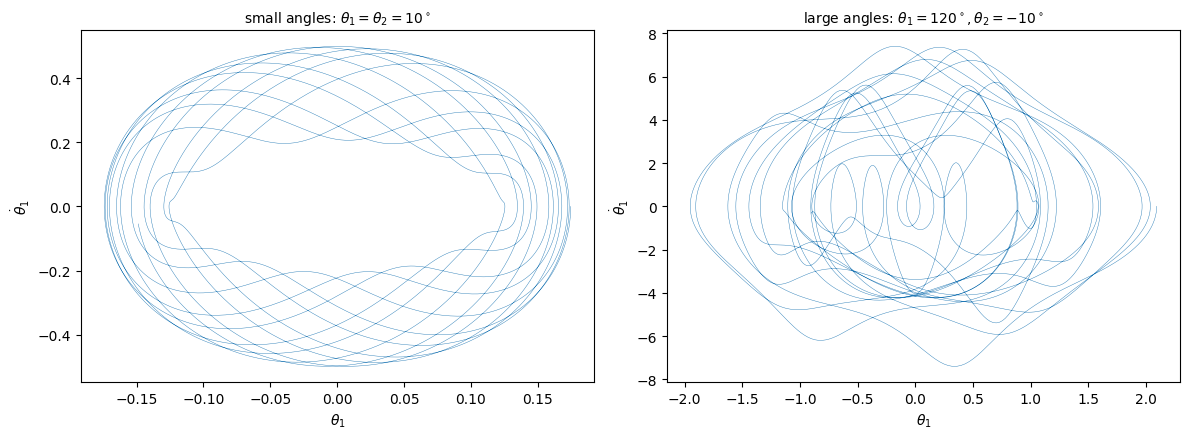

In [28]:
q0_pair = np.deg2rad([[10.0, 120.0], [10.0, -10.0]])        # columns: (10, 10) deg and (120, -10) deg
_, Qp, Wp = simulate(accel_dp, q0_pair, np.zeros((2, 2)), T=30.0, dt=5e-3)
titles = [r"small angles: $\theta_1=\theta_2=10^\circ$", r"large angles: $\theta_1=120^\circ, \theta_2=-10^\circ$"]
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for j, (ax, title) in enumerate(zip(axes, titles)):
    ax.plot(Qp[:, 0, j], Wp[:, 0, j], lw=0.3)
    ax.set_xlabel(r"$\theta_1$"); ax.set_ylabel(r"$\dot\theta_1$"); ax.set_title(title, fontsize=10)
fig.tight_layout(); plt.show()

Left (small angles): the curve stays inside a band and is woven in a regular pattern; two oscillations with different frequencies are superposed, and
the trajectory never exactly repeats. Right (large angles): the curve wanders irregularly over a larger region. In both cases the lines cross each other,
because the plot shows only two of the four coordinates. A projection of a chaotic trajectory fills an area and hides the structure. The tool for looking inside is the **Poincaré section**. It is introduced here
step by step.

**1. Phase space and flow.** The state of the double pendulum is the point $z = (\theta_1, \theta_2, \dot\theta_1, \dot\theta_2) \in \mathbb R^4$. The equations of motion
$\dot z = F(z)$ determine, for every initial state $z_0$, a unique trajectory $z(t) = \varphi_t(z_0)$; the map $\varphi_t$ is called the **flow**. Trajectories
of an autonomous system (one whose equations do not contain the time explicitly, $\dot z = F(z)$ and not $F(z, t)$) never cross each other in phase space:
through every point passes exactly one trajectory.

**2. The energy surface.** The energy $E(z) = T + V$ is conserved, so a trajectory never leaves the 3-dimensional surface $\{z : E(z) = E\}$. Each trajectory is a
curve on this 3D surface, which still cannot be drawn on paper. A projection onto two coordinates, as in the figure above, squashes the curve and makes it
cross itself everywhere.

**3. The surface of section.** Choose a surface that trajectories keep passing through, here
$$\Sigma = \{\, z :\ \theta_1 = 0,\ \ \dot\theta_1 > 0,\ \ E(z) = E \,\}.$$
In words: the first rod passes through the vertical, moving to the right. The condition $\dot\theta_1 > 0$ is needed because during one swing the rod passes the
vertical twice, once in each direction; counting only one direction makes every recorded point correspond to "the same phase" of the motion, and it guarantees
that the trajectory really crosses $\Sigma$ instead of touching it. $\Sigma$ is **2-dimensional**: $\theta_1 = 0$ removes one coordinate, and on this set the energy
equation, quadratic in $\dot\theta_1$, fixes $\dot\theta_1 > 0$ once $\theta_2$ and $\dot\theta_2$ are given (the formula is derived below). The pair $(\theta_2, \dot\theta_2)$ is therefore a
complete set of coordinates on $\Sigma$ (up to a two-fold ambiguity where both roots of the quadratic are positive; we then take the larger one, see below).

**4. The Poincaré map.** Start at a point $z \in \Sigma$, follow the flow, and stop when the trajectory comes back to $\Sigma$ for the first time; call this time
$\tau(z)$, the **return time**. The point of return defines the **Poincaré map**
$$P : \Sigma \to \Sigma, \qquad P(z) = \varphi_{\tau(z)}(z).$$
A trajectory is thus turned into a sequence of points $z_1,\ z_2 = P(z_1),\ z_3 = P(z_2), \dots$ in a plane: a continuous flow in 4 dimensions is replaced by a
**discrete map in 2 dimensions**, without losing information, because every $z_n$ determines the whole trajectory through it.

**5. What the patterns mean.**
- A **periodic orbit** that crosses $\Sigma$ $k$ times per period returns to the same $k$ points: a fixed point of $P^k$ (the map applied $k$ times).
- **Quasi-periodic motion** combines two frequencies whose ratio is irrational; the trajectory then winds forever around a 2-dimensional **torus** in phase space
  without closing. (Each of the two oscillations is described by a phase angle that runs around a circle; the pair of angles lives on the surface of a
  doughnut, the torus.) The torus intersects $\Sigma$ in a closed curve, and the points $z_n$ fill this **invariant curve** densely.
- **Chaotic motion** lies on no torus; its points $z_n$ scatter over a **2-dimensional region** of $\Sigma$.

For small oscillations the double pendulum is close to two coupled harmonic oscillators (Exercise 2), and all motion is quasi-periodic. With growing energy the
nonlinearity grows; the **Kolmogorov–Arnold–Moser (KAM) theorem** states that most tori survive a weak perturbation but are progressively destroyed as it becomes
stronger, leaving chains of islands (remnants of resonant tori) embedded in a chaotic sea. The four panels below show this sequence.

**6. A remark on coordinates.** For Hamiltonian systems (conservative systems without friction, such as all systems described by a Lagrangian $L = T - V$)
the Poincaré map **preserves area**, but in the canonical coordinates $(\theta_2, p_2)$ with the canonical
momentum $p_2 = \partial L / \partial\dot\theta_2$ (for a single particle $\partial L/\partial\dot x = m\dot x$, the ordinary momentum, Section 2), which on $\Sigma$ (with $m = l = 1$) equals $\dot\theta_2 + \dot\theta_1\cos\theta_2$. We plot $(\theta_2, \dot\theta_2)$, which
is more intuitive; it shows the same curves, islands and chaotic regions, but areas are slightly distorted.

**7. How the crossings are found numerically.** The integrator produces states $z_n$ at times $t_n = n\,\Delta t$. A crossing of $\Sigma$ between steps $n$ and $n+1$
is detected by a sign change of $s = \sin\theta_1$ from $s_n < 0$ to $s_{n+1} \ge 0$ (the rod moves to the right) together with $\cos\theta_1 > 0$ (the rod
points down; this excludes the passage through the upright position $\theta_1 = \pi$, where $\sin\theta_1$ also changes sign). The sine is tested instead
of $\theta_1$ itself because the integrator does not reduce the angle to one period: after the first rod has gone over the top, $\theta_1$ continues to
$2\pi, 4\pi, \dots$, and $\sin\theta_1$ detects every passage through the downward vertical, modulo $2\pi$. Within the step the motion is
approximated by a straight line: the crossing happens at the fraction
$$\beta = \frac{s_n}{s_n - s_{n+1}} \in (0, 1]$$
of the step, and the state on $\Sigma$ is estimated as $z^\ast \approx z_n + \beta\,(z_{n+1} - z_n)$. The error of this linear interpolation is of order
$\Delta t^2$ (here $\Delta t = 10^{-2}$ s). We measured it by locating the crossings exactly (by repeating the last step with an adjusted step size until
$\sin\theta_1 = 0$): the typical error in $\dot\theta_2$ is below $10^{-3}$ rad/s and the largest about $2\cdot10^{-2}$ rad/s, invisible on axes that span
$\pm 10$ rad/s.
The angle $\theta_2$ is also brought back to one period with `np.arctan2(np.sin(th2), np.cos(th2))`: `arctan2` returns the angle in $(-\pi, \pi]$ with the
given sine and cosine, i.e. $\theta_2$ shifted by a multiple of $2\pi$.

**Initial conditions at fixed energy.** We start every trajectory on the section: choose $\theta_1 = 0$, a random $\theta_2$ and $\dot\theta_2$, and compute $\dot\theta_1>0$ from $E$.
With $m = l = 1$, the energy at $\theta_1 = 0$ is
$$E = \dot\theta_1^2 + \dot\theta_1\dot\theta_2\cos\theta_2 + \tfrac12\dot\theta_2^2 - 2g - g\cos\theta_2 ,$$
a quadratic equation for $\dot\theta_1$. We let SymPy confirm the formula and solve it.

$\theta_2$ and $\dot\theta_2$ are drawn at random, and a draw is rejected when no real $\dot\theta_1 > 0$ gives the required energy (the energy is too low
for these values); this is called **rejection sampling**. Minimising the kinetic part of the formula over $\dot\theta_1$ (the minimum is at $\dot\theta_1 = -\tfrac12\dot\theta_2\cos\theta_2$) gives
$E \ge \tfrac14\dot\theta_2^2(2 - \cos^2\theta_2) - 2g - g\cos\theta_2 \ge \tfrac14\dot\theta_2^2 - 3g$, so on the section
$|\dot\theta_2| \le 2\sqrt{E + 3g}$: $4.2$ rad/s at $E = -25$ and $10.8$ rad/s at $E = 0$. The sampling range $\pm 10$ rad/s therefore covers almost the whole
allowed region (at $E = 0$ the narrow strips $10 < |\dot\theta_2| < 10.8$ are not sampled), and at low energy most draws are rejected (about 91 % at
$E = -25$), which costs only a little time. When both roots are positive, both give valid states with the same energy; taking the larger one is an
arbitrary convention.

In [29]:
q1s, q2s = dp["q"]; w1s, w2s = dp["w"]
E_sec = dp["E"].subs({**dict(zip(dp["m"], [1, 1])), **dict(zip(dp["l"], [1, 1]))}).subs(q1s, 0)
show(r"E\big|_{\theta_1 = 0} = ", sp.expand(sp.simplify(E_sec)))

E_sym = sp.symbols("E")
roots = sp.solve(sp.Eq(E_sec, E_sym), w1s)
show(r"\dot\theta_1 = ", roots[0], r"\quad\text{or}\quad", roots[1])
w1_of = sp.lambdify((q2s, w2s, E_sym, dp["g"]), roots, "numpy")     # both roots as NumPy functions

<IPython.core.display.Math object>

<IPython.core.display.Math object>

Two functions: the first creates initial states on the section with a given energy, the second integrates a batch of trajectories and records where they cross the section.
`poincare_sections` integrates the trajectories of **all** requested energies as one batch (4 energies $\times$ 30 trajectories = 120 columns), which costs
little more than a single trajectory. For speed the step is $\Delta t = 10^{-2}$ s and $T = 100$ s (10 000 steps, a few seconds); each trajectory then crosses
the section about 50 times. The accuracy is monitored by the largest energy error at the end, printed in each panel title. These values are kept small for
the free Colab CPU; `T=300.0, dt=5e-3` (about a minute) gives denser and sharper pictures.

New NumPy functions in the code: `np.isfinite` is `True` for ordinary numbers and `False` for `nan` (the square root of a negative number) and infinity;
`np.repeat(energies, n_traj)` repeats every energy `n_traj` times, giving the energy of each column; `np.nonzero(crossed)[0]` gives the column
indices where `crossed` is `True`, so that every section point is stored together with the number of its trajectory.

In [30]:
def initial_conditions_on_section(E, n, rng, g=9.81):
    """n states with theta1 = 0, theta1_dot > 0 and energy E (m = l = 1)."""
    states = []
    while len(states) < n:
        th2, w2 = rng.uniform(-np.pi, np.pi), rng.uniform(-10, 10)
        with np.errstate(invalid="ignore"):                 # sqrt of a negative number -> nan (energy not reachable)
            w1_candidates = np.array(w1_of(th2, w2, E, g), dtype=float)
        w1_ok = w1_candidates[np.isfinite(w1_candidates) & (w1_candidates > 0)]
        if w1_ok.size > 0:
            states.append([0.0, th2, w1_ok.max(), w2])       # if both roots are positive, take the larger one
    return np.array(states).T                               # shape (4, n): rows q1, q2, w1, w2

def poincare_sections(energies, n_traj=30, T=100.0, dt=1e-2, seed=0):
    """n_traj trajectories for each energy, all integrated as one batch; collect crossings of theta1 = 0 with theta1_dot > 0.
    Returns the points (column index, theta2, theta2_dot) and the largest energy error for each energy."""
    rng = np.random.default_rng(seed)
    s = np.hstack([initial_conditions_on_section(E, n_traj, rng) for E in energies])   # shape (4, n_energies * n_traj)
    E_target = np.repeat(energies, n_traj)                  # energy of every column
    q, w = s[:2], s[2:]
    points = []
    for _ in range(int(round(T / dt))):
        q_new, w_new = rk4_step(accel_dp, q, w, dt)
        # crossing: sin(theta1) changes sign from - to + while the rod points down (cos theta1 > 0)
        before, after = np.sin(q[0]), np.sin(q_new[0])
        crossed = (before < 0) & (after >= 0) & (np.cos(q_new[0]) > 0)
        if crossed.any():
            frac = before[crossed] / (before[crossed] - after[crossed])        # linear interpolation in time
            th2 = q[1, crossed] + frac * (q_new[1, crossed] - q[1, crossed])
            w2 = w[1, crossed] + frac * (w_new[1, crossed] - w[1, crossed])
            th2 = np.arctan2(np.sin(th2), np.cos(th2))                       # wrap the angle to (-pi, pi]
            points += list(zip(np.nonzero(crossed)[0], th2, w2))
        q, w = q_new, w_new
    dE = np.abs(energy_dp(q, w) - E_target).reshape(len(energies), n_traj).max(axis=1)
    return np.array(points), dE

print("minimum energy (both rods hanging down):", -3 * 9.81)

minimum energy (both rods hanging down): -29.43


**Section versus projection, for a single trajectory.** Before computing many trajectories, the difference between a projection and a section is shown for one
regular trajectory ($E = -25$) and one chaotic trajectory ($E = 0$), integrated together as a batch of two for 80 s with $\Delta t = 10^{-2}$ s. Left: the whole trajectory projected onto the plane
$(\theta_2, \dot\theta_2)$ (thin line), with the crossings of the section $\theta_1 = 0$, $\dot\theta_1 > 0$ marked as dots. Right: the crossings alone, which is
the Poincaré section of this trajectory. `seed=1` only selects which random initial condition is shown.

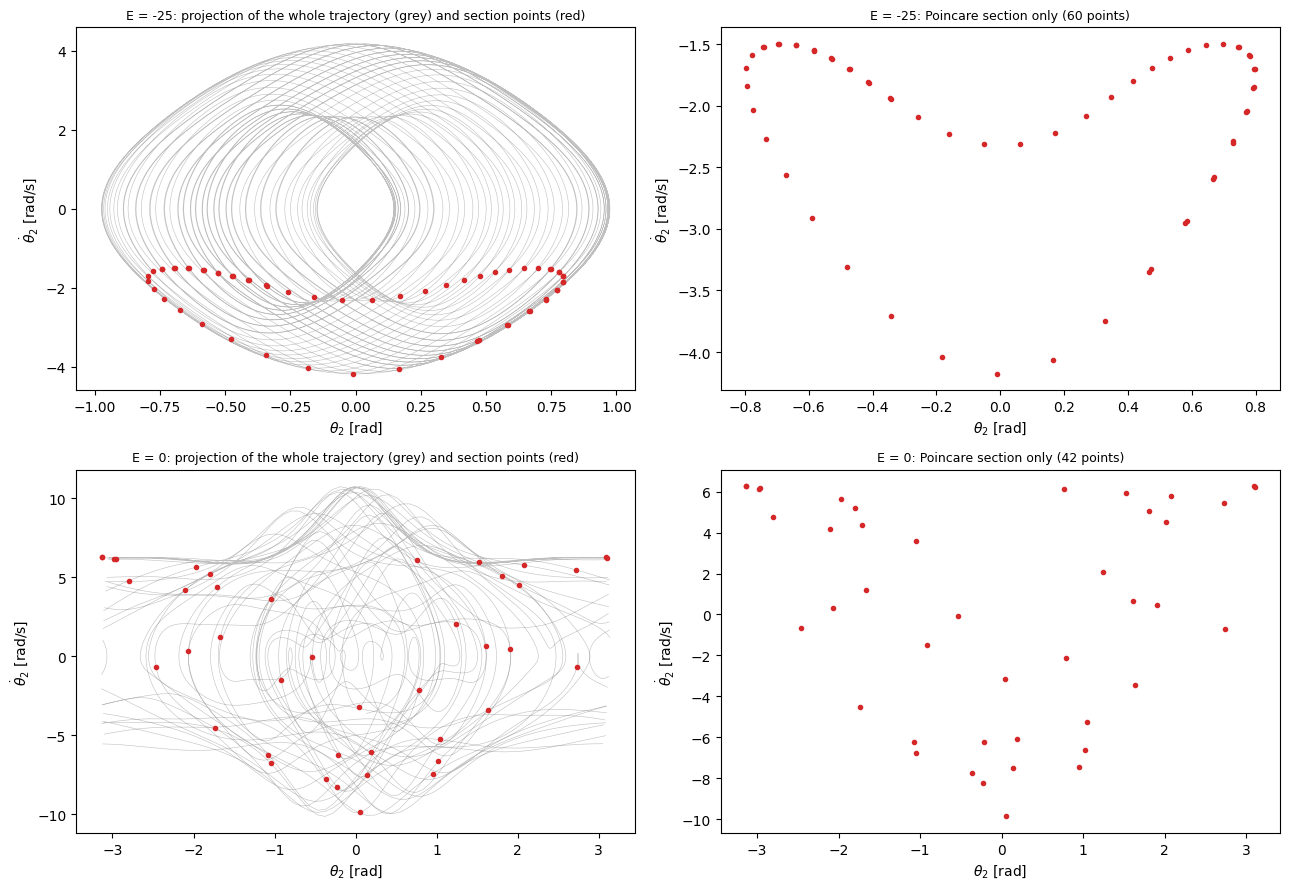

In [31]:
def single_trajectories_and_crossings(energies, T=80.0, dt=1e-2, seed=1):
    # one trajectory per energy, started on the section; returns the full paths and the section points of each
    s0 = np.hstack([initial_conditions_on_section(E, 1, np.random.default_rng(seed)) for E in energies])
    q, w = s0[:2].copy(), s0[2:].copy()                         # shapes (2, number of energies)
    path, crossings = [np.vstack([q, w])], [[] for _ in energies]
    for _ in range(int(round(T / dt))):
        q_new, w_new = rk4_step(accel_dp, q, w, dt)
        before, after = np.sin(q[0]), np.sin(q_new[0])
        for j in np.nonzero((before < 0) & (after >= 0) & (np.cos(q_new[0]) > 0))[0]:   # same condition as above
            frac = before[j] / (before[j] - after[j])
            crossings[j].append([q[1, j] + frac * (q_new[1, j] - q[1, j]), w[1, j] + frac * (w_new[1, j] - w[1, j])])
        q, w = q_new, w_new
        path.append(np.vstack([q, w]))
    return np.array(path), [np.array(c) for c in crossings]         # path: (steps, 4, number of energies)

paths, crossings = single_trajectories_and_crossings([-25.0, 0.0])
fig, axes = plt.subplots(2, 2, figsize=(13, 9))
for row, E in enumerate([-25.0, 0.0]):
    path, cross = paths[:, :, row], crossings[row]
    th2 = np.arctan2(np.sin(path[:, 1]), np.cos(path[:, 1]))        # theta2 wrapped to (-pi, pi]
    th2[1:][np.abs(np.diff(th2)) > np.pi] = np.nan                   # break the line where the angle jumps by 2 pi
    axes[row, 0].plot(th2, path[:, 3], color="0.75", lw=0.4)
    axes[row, 0].plot(np.arctan2(np.sin(cross[:, 0]), np.cos(cross[:, 0])), cross[:, 1], "o", color="C3", ms=3)
    axes[row, 0].set_title(f"E = {E:g}: projection of the whole trajectory (grey) and section points (red)", fontsize=9)
    axes[row, 1].plot(np.arctan2(np.sin(cross[:, 0]), np.cos(cross[:, 0])), cross[:, 1], "o", color="C3", ms=3)
    axes[row, 1].set_title(f"E = {E:g}: Poincaré section only ({len(cross)} points)", fontsize=9)
    for ax in axes[row]:
        ax.set_xlabel(r"$\theta_2$ [rad]"); ax.set_ylabel(r"$\dot\theta_2$ [rad/s]")
fig.tight_layout(); plt.show()

In the projection (left) the trajectory crosses itself everywhere, although in the 4D phase space it never does: the projection discards two coordinates.
The section (right) keeps only the moments at which the state passes through the same surface, and there the structure is clear: for the regular trajectory
the points line up on a closed curve (the cut through the torus on which the motion takes place), for the chaotic trajectory they scatter over an area.
Each point of the section determines the next one (the *Poincaré map*), so the section is a 2D picture of the dynamics, not of a single moment.

Four energies, from slightly above the minimum $E_{\min} = -3g \approx -29.4$ to $E = 0$. For orientation: released from rest with
$\theta_1 = \theta_2 = \alpha$, the pendulum has $E = -3g\cos\alpha$, so $E = -25, -15, -10, 0$ correspond to $\alpha \approx 32^\circ, 59^\circ, 70^\circ, 90^\circ$
(both rods horizontal at $E = 0$). The values were picked to show the regular, mixed and chaotic regimes; nearby values show the same picture. Each panel:
30 trajectories, 100 s each, one colour per trajectory (colours repeat after 20).

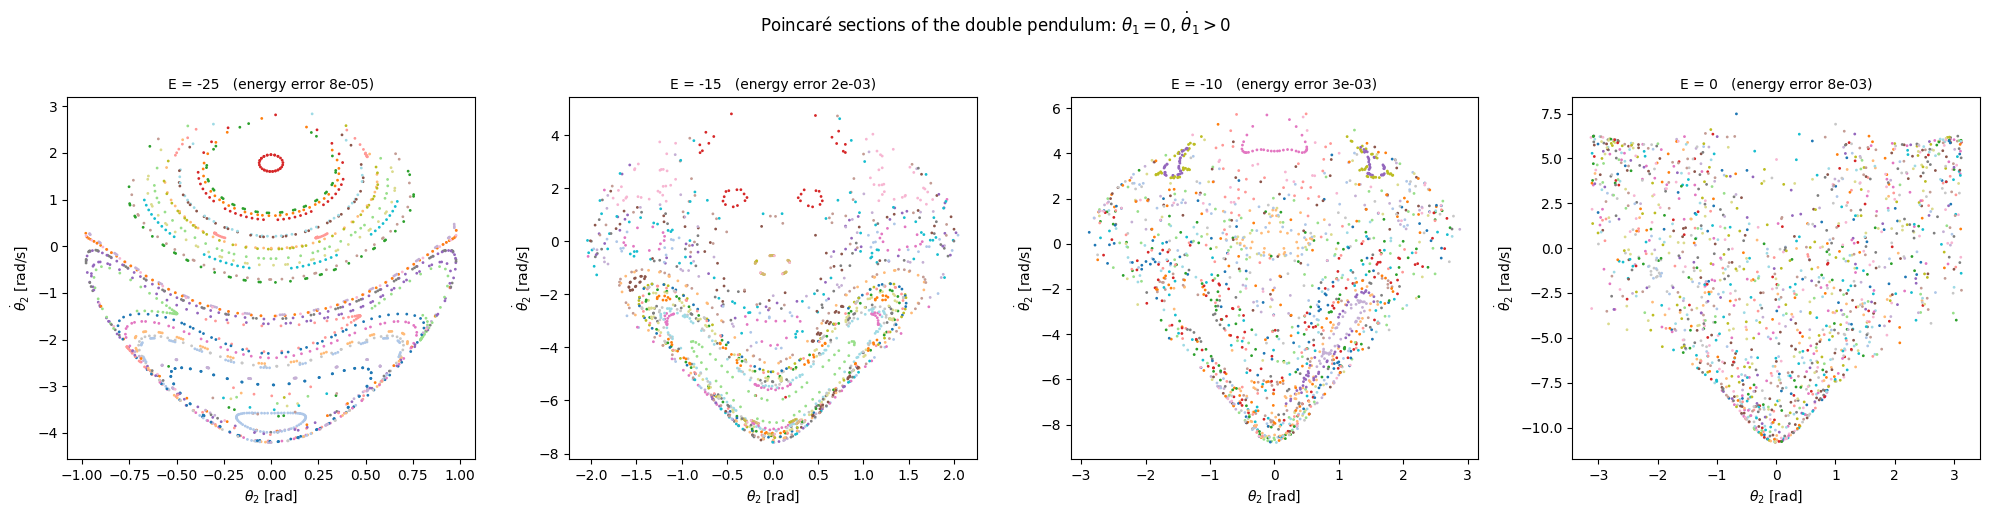

computed in 5 s


In [32]:
energies = [-25.0, -15.0, -10.0, 0.0]
n_traj = 30
t0 = time.perf_counter()
pts, dE = poincare_sections(energies, n_traj=n_traj)
fig, axes = plt.subplots(1, 4, figsize=(20, 5))
for k, (ax, E) in enumerate(zip(axes, energies)):
    mine = (pts[:, 0] >= k * n_traj) & (pts[:, 0] < (k + 1) * n_traj)        # columns that belong to energy k
    ax.scatter(pts[mine, 1], pts[mine, 2], c=pts[mine, 0] % 20, cmap="tab20", vmin=0, vmax=19, s=1.0)
    ax.set_title(f"E = {E:g}   (energy error {dE[k]:.0e})", fontsize=10)
    ax.set_xlabel(r"$\theta_2$ [rad]"); ax.set_ylabel(r"$\dot\theta_2$ [rad/s]")
fig.suptitle(r"Poincaré sections of the double pendulum: $\theta_1 = 0$, $\dot\theta_1 > 0$", y=1.02)
fig.tight_layout(); plt.show()
print(f"computed in {time.perf_counter() - t0:.0f} s")

**Interpretation.**
- $E = -25$ (small oscillations): every trajectory draws a closed curve or a chain of small islands — the motion is regular. Near the minimum the double pendulum is close to
  two coupled harmonic oscillators (Exercise 2).
- $E = -15$: closed curves and chains of small islands coexist with regions of scattered points — **mixed phase space**.
- $E = -10$: most of the section is a chaotic sea; a few islands of regular motion survive.
- $E = 0$: almost all initial conditions are chaotic.

How to read the panels: points of one colour belong to one trajectory (with 30 trajectories and 20 colours, two trajectories share a colour). A regular
trajectory puts all its points on one curve, a chaotic one scatters them. The points fill a region whose outer edge is the edge of the energetically
allowed part of $\Sigma$. It is not symmetric under $\dot\theta_2 \to -\dot\theta_2$ because of the condition $\dot\theta_1 > 0$: from the quadratic
equation above, at $\theta_2 = 0$ and $E = -25$ the allowed range is $-4.2 < \dot\theta_2 < 3.0$ rad/s, in agreement with the vertical extent of the points in the first panel.

The gradual break-up of the invariant curves with growing perturbation is described by the Kolmogorov–Arnold–Moser (KAM) theorem.

<hr/>
## 9. A 5-link chain with autodiff only

For $N = 5$ we skip SymPy: the accelerations come from the Lagrangian alone, by autodiff. We integrate **20 chains** at once: all released horizontally
($\theta_i = 90^\circ$), with the first angle shifted by $k\cdot 10^{-4}$ rad, $k=0,\dots,19$.

`accel_from_lagrangian` of Section 5 is written for **one** state: one Hessian and one linear solve. `vmap` turns it into a function that processes a whole
batch along the first axis, without rewriting it. This is exact but slow: every call of the `torch.func` transformations carries a fixed overhead of
of order 10 ms (about 8 ms in the run of Section 5), and RK4 needs four calls per step, i.e. thousands of calls for one simulation. For long simulations we therefore write a
second, batched version, `accel_batch`, with `torch.autograd.grad`, which computes the same quantities with fewer and cheaper passes:
- The chains are independent, so the gradient of the **sum** of their Lagrangians with respect to `q` (shape `(B, N)`) contains $\partial L_b/\partial q$ for every
  chain $b$ at once; the same holds for `qd`. `lagrangian_chain` sums over the last axis, so it already returns the $B$ Lagrangians of a batch.
- `create_graph=True` keeps the computational graph of these first derivatives, so that they can be differentiated once more.
- Differentiating $\sum_b \partial L_b/\partial\dot q_{b,i}$ with respect to `qd` and `q` gives row $i$ of $M$ and row $i$ of $C$ for all chains; $N$ such passes give the
  whole matrices. `retain_graph=True` keeps the graph alive between the passes.
- `.detach()` returns the result without the graph, as plain numbers.

The first cell checks that both versions agree and compares their cost.

In [33]:
N_chain, n_copies = 5, 20
m_c, l_c, g_c = torch.ones(N_chain), torch.full((N_chain,), 0.4), 9.81
L_chain = lambda q, qd: lagrangian_chain(q, qd, m_c, l_c, g_c)

def accel_batch(L, q, qd):
    """Accelerations of B independent systems; q and qd have shape (B, N), L(q, qd) returns the B Lagrangians."""
    q = q.detach().requires_grad_(True)
    qd = qd.detach().requires_grad_(True)
    dL_dq, dL_dqd = torch.autograd.grad(L(q, qd).sum(), (q, qd), create_graph=True)
    M_rows, C_qd = [], []
    for i in range(q.shape[1]):
        # row i of M and of C, for all chains at once: derivatives of dL/dqd_i with respect to qd and q
        d_q, d_qd = torch.autograd.grad(dL_dqd[:, i].sum(), (q, qd), retain_graph=True)
        M_rows.append(d_qd)
        C_qd.append((d_q * qd).sum(dim=1))                  # (C qd)_i for every chain
    M, C_qd = torch.stack(M_rows, dim=1), torch.stack(C_qd, dim=1)       # shapes (B, N, N) and (B, N)
    return torch.linalg.solve(M, dL_dq - C_qd).detach()

# the torch.func version of Section 5, applied to a batch with vmap
accel_vmap = vmap(lambda q, qd: accel_from_lagrangian(L_chain, q, qd))

torch.manual_seed(0)
q_test, qd_test = 3 * torch.rand(n_copies, N_chain), torch.randn(n_copies, N_chain)     # random test states
print(f"max |accel_vmap - accel_batch| = {(accel_vmap(q_test, qd_test) - accel_batch(L_chain, q_test, qd_test)).abs().max():.1e}")
for name, f in [("vmap(accel_from_lagrangian)", lambda: accel_vmap(q_test, qd_test)),
                ("accel_batch", lambda: accel_batch(L_chain, q_test, qd_test))]:
    f()                                                     # warm-up call
    t0 = time.perf_counter()
    for _ in range(10):
        f()
    print(f"{name:28s}: {1e3 * (time.perf_counter() - t0) / 10:.1f} ms per call for {n_copies} chains")

max |accel_vmap - accel_batch| = 3.6e-14
vmap(accel_from_lagrangian) : 9.7 ms per call for 20 chains
accel_batch                 : 1.4 ms per call for 20 chains


The simulation uses `accel_batch`. Choices: with $l_i = 0.4$ the chain has total length 2, the same as the double pendulum with $l = 1$, so the pictures have
the same scale. The step $\Delta t = 8\cdot10^{-3}$ s resolves the time scale $\sqrt{l/g} \approx 0.2$ s with 25 steps and keeps the cell at a few seconds.
The energy error at the end is printed; the chains start horizontally, where $E = 0$, so it is an absolute error, to be compared with the potential energy,
which changes by up to about 60 during the motion. Halving the step reduces the error about 20 times (with twice the run time). $T = 6$ s is long enough
for the chains to separate. `energy_chain` also sums over the last axis, so it accepts the whole batch.

In [34]:
def accel_chain(q, w):
    """NumPy wrapper with the (N, B) layout used by rk4_step (accel_batch uses (B, N), hence the transposes .T)."""
    return accel_batch(L_chain, torch.tensor(q.T), torch.tensor(w.T)).numpy().T

q = np.full((N_chain, n_copies), np.pi / 2)
q[0] += 1e-4 * np.arange(n_copies)                       # small differences in the first angle
w = np.zeros((N_chain, n_copies))
E_start = energy_chain(torch.tensor(q.T), torch.tensor(w.T), m_c, l_c, g_c).numpy()

dt, T_end = 8e-3, 6.0
n_steps = int(round(T_end / dt))
snapshot_steps = [int(round(t / dt)) for t in (0, 2, 4, 6)]     # store the configuration at t = 0, 2, 4, 6 s
snapshots, frames_chain0 = {}, []
t0 = time.perf_counter()
for step in range(n_steps + 1):
    if step in snapshot_steps:
        snapshots[step * dt] = q.copy()
    if step % 10 == 0:                                       # every 0.08 s: angles of chain 0, for the animation
        frames_chain0.append(q[:, 0].copy())
    if step < n_steps:
        q, w = rk4_step(accel_chain, q, w, dt)
E_end = energy_chain(torch.tensor(q.T), torch.tensor(w.T), m_c, l_c, g_c).numpy()
print(f"integration took {time.perf_counter() - t0:.0f} s;  max energy error: {np.max(np.abs(E_end - E_start)):.1e}")

integration took 5 s;  max energy error: 2.8e-02


Snapshots of the 20 chains at $t = 0, 2, 4, 6$ s:

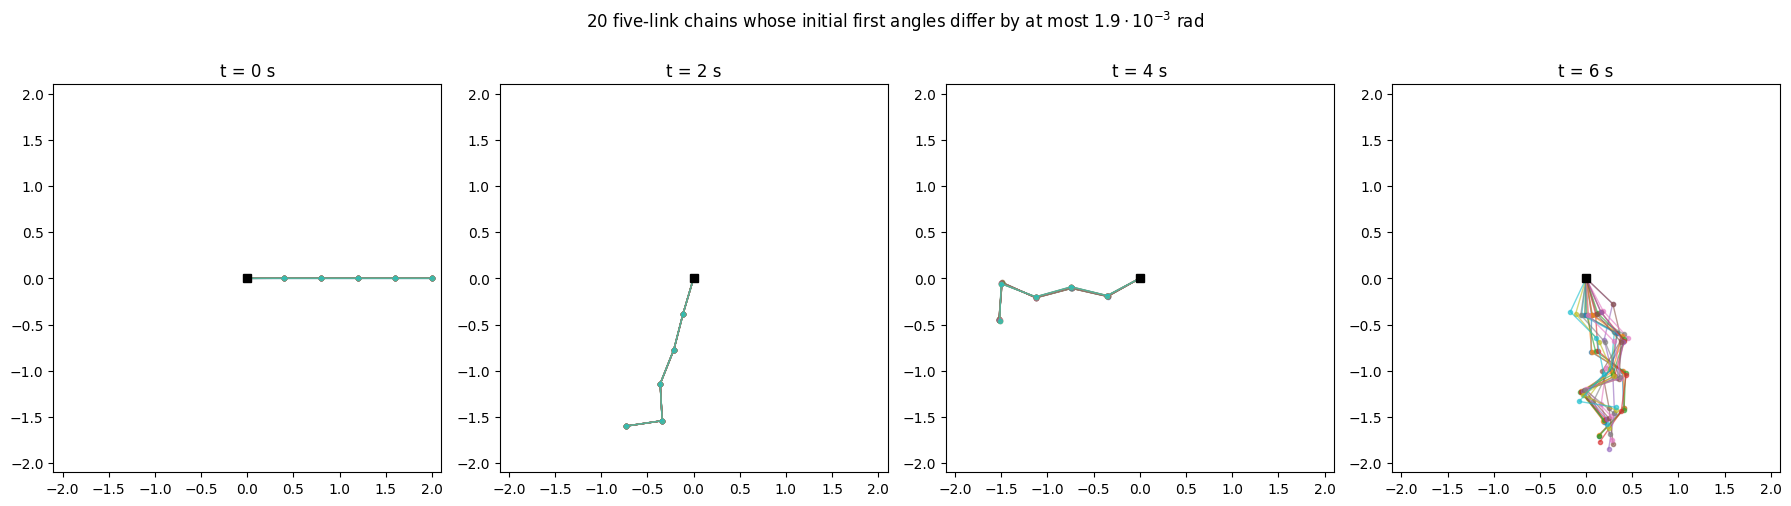

In [35]:
fig, axes = plt.subplots(1, 4, figsize=(18, 4.8))
reach = float(l_c.sum()) * 1.05
for ax, (t_snap, qs) in zip(axes, snapshots.items()):
    X = np.cumsum(l_c.numpy()[:, None] * np.sin(qs), axis=0)       # (N, copies)
    Y = -np.cumsum(l_c.numpy()[:, None] * np.cos(qs), axis=0)
    for k in range(n_copies):
        ax.plot(np.r_[0, X[:, k]], np.r_[0, Y[:, k]], "-o", ms=3, lw=1, alpha=0.6)   # np.r_[0, a]: the array a with 0 (the pivot) in front
    ax.plot(0, 0, "ks")
    ax.set_xlim(-reach, reach); ax.set_ylim(-reach, reach); ax.set_aspect("equal")
    ax.set_title(f"t = {t_snap:.0f} s")
fig.suptitle("20 five-link chains whose initial first angles differ by at most $1.9\\cdot10^{-3}$ rad", y=1.02)
fig.tight_layout(); plt.show()

An animation of one of the chains (chain 0), with the recent path of the tip:

In [36]:
from matplotlib import animation
from IPython.display import HTML

l_np = l_c.numpy()
fig, ax = plt.subplots(figsize=(4.5, 4.5), dpi=50)          # small figure and low resolution keep the file small
reach = l_np.sum() * 1.05
ax.set_xlim(-reach, reach); ax.set_ylim(-reach, reach); ax.set_aspect("equal"); ax.set_xticks([]); ax.set_yticks([])
ax.plot([-0.3, 0.3], [0, 0], "k", lw=3)                                # ceiling
chain_line, = ax.plot([], [], "o-", color="C0", lw=2.5, ms=7, mec="k")
tip_trail, = ax.plot([], [], "-", color="C1", lw=1.2, alpha=0.7)
time_label = ax.text(0.03, 0.95, "", transform=ax.transAxes, fontsize=11)
tip_x = [np.sum(l_np * np.sin(qf)) for qf in frames_chain0]
tip_y = [-np.sum(l_np * np.cos(qf)) for qf in frames_chain0]

def update(i):
    qf = frames_chain0[i]
    xs = np.r_[0, np.cumsum(l_np * np.sin(qf))]
    ys = np.r_[0, -np.cumsum(l_np * np.cos(qf))]
    chain_line.set_data(xs, ys)
    start = max(0, i - 25)                                             # tip path of the last 2 s (25 frames of 0.08 s)
    tip_trail.set_data(tip_x[start:i + 1], tip_y[start:i + 1])
    time_label.set_text(f"t = {i * 10 * dt:.2f} s")
    return chain_line, tip_trail, time_label

anim = animation.FuncAnimation(fig, update, frames=len(frames_chain0), interval=80, blit=True)
plt.close(fig)
HTML(anim.to_jshtml(default_mode="once"))

Up to $t \approx 4$ s the 20 chains are indistinguishable in the plot; by $t = 6$ s they have separated.
Compare with the double pendulum of Section 7, where a difference of $10^{-9}$ needed about 19 s to become visible: here differences of $10^{-4}$–$10^{-3}$
become visible after about 5 s. With exponential growth $d(t)\sim d_0 e^{\lambda t}$, the time to reach a visible separation grows only like $\ln(1/d_0)/\lambda$, so both observations
are consistent with exponents of order $1\,\mathrm{s}^{-1}$. Exercise 3 introduces a quantitative measure.

<hr/>
## 10. Summary
- **SymPy**: symbols, `simplify`, `diff`, `solve`, `Matrix`, `dsolve`, `lambdify`. Exact formulas, but expressions and derivation time grow quickly with system size.
- **Lagrangian mechanics**: $L = T - V$ in generalised coordinates, Euler–Lagrange equations; for the $N$-link pendulum they take the form $M(q)\ddot q = F(q,\dot q)$.
- **Autodiff**: $\ddot q = M^{-1}\big(\nabla_q L - (\nabla_q\nabla_{\dot q}L)\dot q\big)$ with $M = \nabla_{\dot q}\nabla_{\dot q} L$ — only $L$ has to be written.
  Agreement with SymPy to $10^{-13}$.
- **Numerics**: RK4 with error $\propto\Delta t^4$; energy conservation as a test.
- **Dynamics**: exponential separation of nearby trajectories (Lyapunov exponent); Poincaré sections show the transition from regular to chaotic motion with growing energy.

<hr/>
## 11. Exercises (with solutions)

### Exercise 1 — The elastic pendulum
Replace the rigid rod of the single pendulum by a spring of stiffness $k$ and rest length $l_0$. The generalised coordinates are the length $r$ and the angle $\varphi$:
$$L = \tfrac12 m\big(\dot r^2 + r^2\dot\varphi^2\big) + m g\, r\cos\varphi - \tfrac12 k\,(r - l_0)^2 .$$
1. Derive the two Euler–Lagrange equations with SymPy and solve them for $\ddot r$ and $\ddot\varphi$.
2. Write the same Lagrangian as a PyTorch function of `q = (r, phi)`, `qd = (r_dot, phi_dot)` and check that `accel_from_lagrangian` gives the same accelerations at a few random states.
3. Simulate $m=1$, $k=40$, $l_0=1$, $g=9.81$ from $r = 1.2$, $\varphi = 0.6$, at rest, for 20 s ($\Delta t = 2\cdot10^{-3}$ s) with the SymPy accelerations. Plot the path of the mass in the $(x, y)$ plane and check energy conservation.

The parameters are arbitrary. With $k = 40$ the spring oscillates with $\sqrt{k/m} \approx 6.3$ rad/s, and the pendulum, whose length at equilibrium is
$l_0 + mg/k \approx 1.25$, with $\sqrt{g/1.25} \approx 2.8$ rad/s; the two motions have comparable frequencies and are coupled, so the mass does not move on a simple arc but traces loops.

In the solution, `sp.solve(equations, unknowns, dict=True)` returns a list of dictionaries `{unknown: value}`, one per solution; `[0]` takes the only one.

#### Solution

<IPython.core.display.Math object>

<IPython.core.display.Math object>

SymPy: [ 8.87665341 -2.55120653]   autodiff: [ 8.87665341 -2.55120653]
SymPy: [17.32871922  3.01864123]   autodiff: [17.32871922  3.01864123]
SymPy: [3.78776318 7.27982747]   autodiff: [3.78776318 7.27982747]


relative energy drift: 2.2e-11


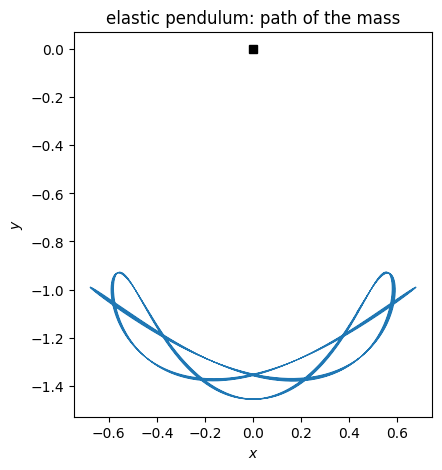

In [37]:
# 1) SymPy derivation
t = sp.symbols("t", real=True)
m, g, k, l0 = sp.symbols("m g k l_0", positive=True)
r = sp.Function("r")(t); phi = sp.Function("varphi")(t)
L_el = (sp.Rational(1, 2) * m * (sp.diff(r, t)**2 + r**2 * sp.diff(phi, t)**2)
        + m * g * r * sp.cos(phi) - sp.Rational(1, 2) * k * (r - l0)**2)
EL = [sp.diff(sp.diff(L_el, sp.diff(c, t)), t) - sp.diff(L_el, c) for c in (r, phi)]
sol = sp.solve(EL, [sp.diff(r, t, 2), sp.diff(phi, t, 2)], dict=True)[0]
r_dd, phi_dd = sp.simplify(sol[sp.diff(r, t, 2)]), sp.simplify(sol[sp.diff(phi, t, 2)])
show(r"\ddot r = ", r_dd)
show(r"\ddot\varphi = ", phi_dd)

# replace functions by plain symbols, then lambdify with the parameters fixed
R, P, Rd, Pd = sp.symbols("R P R_d P_d")
to_plain = lambda e: e.subs({sp.diff(r, t): Rd, sp.diff(phi, t): Pd}).subs({r: R, phi: P})
par = {m: 1.0, g: 9.81, k: 40.0, l0: 1.0}
acc_r = sp.lambdify((R, P, Rd, Pd), to_plain(r_dd).subs(par), "numpy")
acc_p = sp.lambdify((R, P, Rd, Pd), to_plain(phi_dd).subs(par), "numpy")
def accel_elastic(q, w):
    return np.array([acc_r(q[0], q[1], w[0], w[1]), acc_p(q[0], q[1], w[0], w[1])])

# 2) the same Lagrangian for autodiff (r = q[0], phi = q[1])
def L_elastic_torch(q, qd, m=1.0, g=9.81, k=40.0, l0=1.0):
    return 0.5 * m * (qd[0]**2 + q[0]**2 * qd[1]**2) + m * g * q[0] * torch.cos(q[1]) - 0.5 * k * (q[0] - l0)**2

rng = np.random.default_rng(1)
for _ in range(3):
    q = np.array([rng.uniform(0.5, 1.5), rng.uniform(-1, 1)]); w = rng.uniform(-2, 2, 2)
    a_ad = accel_from_lagrangian(L_elastic_torch, torch.tensor(q), torch.tensor(w)).numpy()
    print("SymPy:", accel_elastic(q, w), "  autodiff:", a_ad)

# 3) simulation and energy check
t_arr, Q, W = simulate(accel_elastic, [1.2, 0.6], [0.0, 0.0], T=20.0, dt=2e-3)
E = 0.5 * (W[:, 0]**2 + Q[:, 0]**2 * W[:, 1]**2) - 9.81 * Q[:, 0] * np.cos(Q[:, 1]) + 0.5 * 40 * (Q[:, 0] - 1)**2
print(f"relative energy drift: {np.max(np.abs(E - E[0])) / abs(E[0]):.1e}")
fig, ax = plt.subplots(figsize=(5, 5))
ax.plot(Q[:, 0] * np.sin(Q[:, 1]), -Q[:, 0] * np.cos(Q[:, 1]), lw=0.6)
ax.plot(0, 0, "ks"); ax.set_aspect("equal"); ax.set_xlabel("$x$"); ax.set_ylabel("$y$")
ax.set_title("elastic pendulum: path of the mass"); plt.show()

### Exercise 2 — Normal modes of the N-link pendulum
For small oscillations around $q = 0$ the Lagrangian is quadratic,
$L \approx \tfrac12\dot q^{\top} M_0\,\dot q - \tfrac12 q^{\top} K q$ with $M_0 = \partial^2 L/\partial\dot q\,\partial\dot q\,\big|_{0}$ and $K = -\partial^2 L/\partial q\,\partial q\,\big|_{0}$.
The Euler–Lagrange equations of this quadratic Lagrangian are linear, $M_0\ddot q = -K q$. Inserting the ansatz $q(t) = v\cos\omega t$ (all angles
oscillate with one frequency and fixed amplitude ratios $v$) gives $-\omega^2 M_0 v\cos\omega t = -K v\cos\omega t$, so the normal modes solve the generalised
eigenvalue problem $K v = \omega^2 M_0 v$.
1. For $N=2$, $m_1=m_2=m$, $l_1=l_2=l$: compute $M_0$ and $K$ with SymPy (from `dp["M"]` and the energy) and show that $\omega^2 = \frac{g}{l}(2\mp\sqrt2)$.
2. Compute $M_0$ and $K$ by autodiff (`hessian` of `lagrangian_chain`) for $N = 2$ and check the numbers; then for $N = 5$ ($m_i = 1$, $l_i = 0.4$) compute all frequencies with `scipy.linalg.eigh(K, M0)` and draw the five mode shapes.
   `scipy.linalg.eigh(K, M0)` solves the generalised eigenvalue problem $K v = \omega^2 M_0 v$ for a symmetric $K$ and a positive-definite $M_0$; it returns
   the values $\omega^2$ in increasing order and the vectors $v$ as the columns of a matrix. In SymPy, `sp.hessian(V, q)` builds the matrix of second
   derivatives $\partial^2 V/\partial q_i\,\partial q_j$.
3. Start the double pendulum ($m=l=1$) at rest in the slow mode with amplitude $0.01$ rad. Check by simulation that the ratio $\theta_2/\theta_1$ stays constant and that the period is $2\pi/\omega_1$.

#### Solution

<IPython.core.display.Math object>

<IPython.core.display.Math object>

autodiff N=2: omega^2 = [ 5.74656495 33.49343505]   exact: 5.746564953119937 33.493435046880066
N=5 frequencies omega [rad/s]: [ 2.542  5.888  9.392 13.183 17.607]


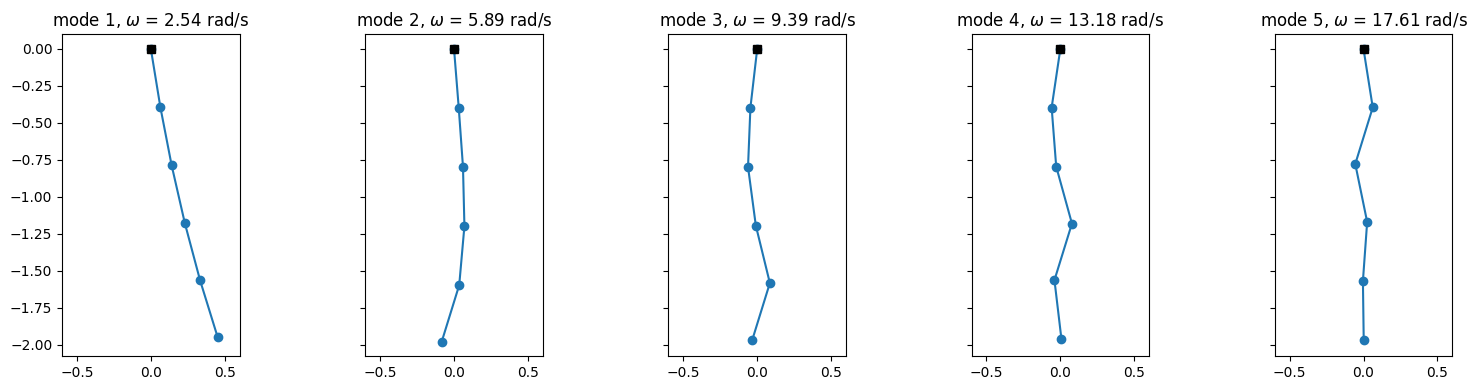

theta2/theta1: expected 1.4142, observed between 1.4141 and 1.4145
period: measured 2.6213 s, 2pi/omega_1 = 2.6211 s


In [38]:
import scipy.linalg

# 1) SymPy, N = 2 with equal masses and lengths
msym, lsym = sp.symbols("m l", positive=True)
eq_par = {dp["m"][0]: msym, dp["m"][1]: msym, dp["l"][0]: lsym, dp["l"][1]: lsym}
zero = {qq: 0 for qq in dp["q"]}
M0_sym = dp["M"].subs(eq_par).subs(zero)
V_sym = dp["E"].subs({ww: 0 for ww in dp["w"]}).subs(eq_par)            # energy at rest = potential energy
K_sym = sp.hessian(V_sym, dp["q"]).subs(zero)                           # K = d^2 V / dq dq at q = 0
show(r"M_0 = ", M0_sym, r",\quad K = ", K_sym)
omega2 = sp.Symbol("omega^2")
roots = sp.solve(sp.det(K_sym - omega2 * M0_sym), omega2)              # det(K - w^2 M0) = 0
show(r"\omega^2 = ", [sp.simplify(rt) for rt in roots])

# 2) autodiff: M0 = d^2L/dqd dqd, K = -d^2L/dq dq, both at q = qd = 0
def M0_K(N, m_vals, l_vals, g=9.81):
    L = lambda q, qd: lagrangian_chain(q, qd, torch.tensor(m_vals), torch.tensor(l_vals), g)
    z = torch.zeros(N)
    return hessian(L, argnums=1)(z, z).numpy(), -hessian(L, argnums=0)(z, z).numpy()

M0, K = M0_K(2, [1.0, 1.0], [1.0, 1.0])
omega_sq2, modes2 = scipy.linalg.eigh(K, M0)                              # generalised eigenproblem: omega^2 and modes
print("autodiff N=2: omega^2 =", omega_sq2, "  exact:", 9.81 * (2 - np.sqrt(2)), 9.81 * (2 + np.sqrt(2)))

M0, K = M0_K(5, [1.0] * 5, [0.4] * 5)
omega_sq5, modes5 = scipy.linalg.eigh(K, M0)
print("N=5 frequencies omega [rad/s]:", np.sqrt(omega_sq5).round(3))
fig, axes = plt.subplots(1, 5, figsize=(16, 4), sharey=True)
for j, ax in enumerate(axes):
    v = modes5[:, j] / np.max(np.abs(modes5[:, j])) * 0.3                # small angles, scaled for display
    X = np.r_[0, np.cumsum(0.4 * np.sin(v))]; Y = np.r_[0, -np.cumsum(0.4 * np.cos(v))]
    ax.plot(X, Y, "-o"); ax.plot(0, 0, "ks"); ax.set_aspect("equal"); ax.set_xlim(-0.6, 0.6)
    ax.set_title(rf"mode {j+1}, $\omega$ = {np.sqrt(omega_sq5[j]):.2f} rad/s")
fig.tight_layout(); plt.show()

# 3) simulation in the slow mode of the double pendulum (m = l = 1)
v1 = modes2[:, 0] / modes2[0, 0]                                          # normalise so that theta1 component = 1
t_arr, Q, W = simulate(accel_dp, 0.01 * v1, [0.0, 0.0], T=10.0, dt=4e-3)    # small oscillations: a larger step is accurate
ratio = Q[:, 1] / Q[:, 0]
ok = np.abs(Q[:, 0]) > 2e-3                                               # avoid dividing by values near zero
print(f"theta2/theta1: expected {v1[1]:.4f}, observed between {ratio[ok].min():.4f} and {ratio[ok].max():.4f}")
up = np.nonzero((Q[:-1, 0] < 0) & (Q[1:, 0] >= 0))[0]                     # upward zero crossings of theta1
print(f"period: measured {np.mean(np.diff(t_arr[up])):.4f} s, 2pi/omega_1 = {2 * np.pi / np.sqrt(omega_sq2[0]):.4f} s")

### Exercise 3 — The largest Lyapunov exponent
The fit in Section 7 is rough. A standard method (Benettin *et al.*, 1980): follow a reference trajectory $A$ and a neighbour $B$ at distance $d_0 = 10^{-8}$;
after every interval $\tau$ measure their distance $d$, add $\ln(d/d_0)$ to a running sum, and move $B$ back to distance $d_0$ along the line joining it with $A$.
Then $\lambda \approx \frac{1}{T}\sum \ln(d/d_0)$ for total time $T$.
The resetting keeps the separation small, so that it always grows at the exponential rate and never saturates. $d_0$ must be small enough that the
separation stays in this linear regime during one interval, yet far above the rounding level $10^{-16}$; $\tau$ must be short enough that $d$ grows only
by a modest factor within it ($e^{\lambda\tau} \approx 1.1$ for $\lambda \approx 1$ s$^{-1}$ and $\tau = 0.1$ s). For this system, $d_0$ between $10^{-9}$ and $10^{-7}$ and $\tau$ between $0.05$ and $1$ s give the same $\lambda$ to three digits (checked for release from rest at $\theta_1=\theta_2=\alpha$ with $\alpha = 90^\circ$ and $130^\circ$).
1. Implement the method for the double pendulum ($m = l = 1$) with $\tau = 0.1$ s, $T = 50$ s, $\Delta t = 10^{-2}$ s. (These values keep the run at a few
   seconds; $T = 200$ s and $\Delta t = 5\cdot10^{-3}$ s give better converged estimates.)
2. Start from rest with $\theta_1 = \theta_2 = \alpha$ for $\alpha = 10^\circ, 30^\circ, \dots, 150^\circ$ and plot $\lambda(\alpha)$. Integrate all angles as one batch.
3. Where does chaos set in? Compare with the Poincaré sections (compute the energy for each $\alpha$).

#### Solution

alpha =    10 deg   E =  -28.98   lambda = 0.004 1/s
alpha =    30 deg   E =  -25.49   lambda = 0.045 1/s
alpha =    50 deg   E =  -18.92   lambda = 0.052 1/s
alpha =    70 deg   E =  -10.07   lambda = 0.070 1/s
alpha =    90 deg   E =   -0.00   lambda = 0.957 1/s
alpha =   110 deg   E =   10.07   lambda = 1.250 1/s
alpha =   130 deg   E =   18.92   lambda = 1.588 1/s
alpha =   150 deg   E =   25.49   lambda = 1.362 1/s


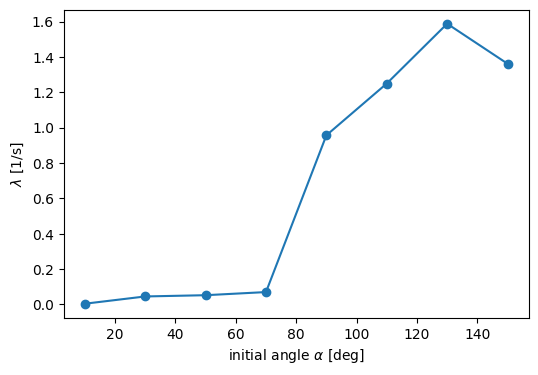

In [39]:
alphas = np.deg2rad(np.arange(10, 151, 20))
n = alphas.size
d0, tau, T_total, dt = 1e-8, 0.1, 50.0, 1e-2
steps_per_tau = int(round(tau / dt))

# reference trajectories A and perturbed trajectories B, all in one batch of 2n states
qA = np.vstack([alphas, alphas]); wA = np.zeros((2, n))
qB = qA + np.array([[d0], [0.0]]);  wB = wA.copy()
q = np.hstack([qA, qB]); w = np.hstack([wA, wB])          # shape (2, 2n): columns 0..n-1 = A, n..2n-1 = B

log_sum = np.zeros(n)
for _ in range(int(T_total / tau)):
    for _ in range(steps_per_tau):
        q, w = rk4_step(accel_dp, q, w, dt)
    # distance between A and B in the 4D phase space
    dq, dw = q[:, n:] - q[:, :n], w[:, n:] - w[:, :n]
    d = np.sqrt(np.sum(dq**2 + dw**2, axis=0))
    log_sum += np.log(d / d0)
    # renormalise: put B back at distance d0 from A, in the same direction
    q[:, n:] = q[:, :n] + dq * d0 / d
    w[:, n:] = w[:, :n] + dw * d0 / d
lyap = log_sum / T_total

E_alpha = energy_dp(np.vstack([alphas, alphas]), np.zeros((2, n)))
for a, E, lam in zip(np.rad2deg(alphas), E_alpha, lyap):
    print(f"alpha = {a:5.0f} deg   E = {E:7.2f}   lambda = {lam:.3f} 1/s")
fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(np.rad2deg(alphas), lyap, "o-")
ax.set_xlabel(r"initial angle $\alpha$ [deg]"); ax.set_ylabel(r"$\lambda$ [1/s]")
plt.show()
# Up to alpha = 70 deg (E <= -10) the estimates are small (below 0.1 1/s); at alpha = 90 deg (E = 0) and above
# lambda is of order 1 1/s: the motion is chaotic. Along this family of initial conditions chaos therefore sets in
# between 70 and 90 deg. Small non-zero values do not prove chaos: for regular motion the finite-time estimate
# decreases roughly like ln(T)/T. Repeating the calculation with larger T distinguishes the two cases.
# The Poincaré section at E = -10 contains both regular islands and a chaotic sea, so at that energy the answer
# depends on the initial condition, not only on the energy.

### Exercise 4 (advanced) — A pendulum made of rigid rods
Replace the point masses by uniform rigid rods of mass $m_k$ and length $l_k$ (no point masses). The kinetic energy of rod $k$ is the energy of its centre of mass
plus the rotational energy about it:
$$T_k = \tfrac12 m_k |\mathbf v_{\mathrm{cm},k}|^2 + \tfrac12\,\frac{m_k l_k^2}{12}\,\dot\theta_k^2,\qquad
\mathbf r_{\mathrm{cm},k} = \mathbf r_{\mathrm{joint},k-1} + \tfrac12 l_k(\sin\theta_k, -\cos\theta_k),$$
and $V = g\sum_k m_k y_{\mathrm{cm},k}$.
1. Write `lagrangian_rods(q, qd, m, l, g)` in PyTorch (*hint:* the velocity of joint $k-1$ is the cumulative sum up to $k$ minus the term of rod $k$).
2. For one rod the exact equation is $\ddot\theta = -\frac{3g}{2l}\sin\theta$. Check `accel_from_lagrangian` against it at random states.
   (Derivation: $m l^2/12$ is the moment of inertia of a uniform rod about its centre; about the pivot it is $m l^2/12 + m (l/2)^2 = m l^2/3$ by the
   parallel-axis theorem. The gravitational torque is $-m g\,(l/2)\sin\theta$, and $\tfrac{m l^2}{3}\ddot\theta = -\tfrac{m g l}{2}\sin\theta$.)
3. Simulate a double rod pendulum ($m_k = 1$, $l_k = 1$) from $\theta_1 = \theta_2 = 90^\circ$ at rest for 3 s ($\Delta t = 10^{-2}$ s) with autodiff
   accelerations (`accel_batch` of Section 9, with a batch of one), and check energy conservation. Nothing except the Lagrangian has to be changed.
   Writing all sums over the last axis (`dim=-1`) makes the functions work for single states and for batches.

#### Solution

single rod: max |autodiff - exact| = 5.3e-15


simulated in 2 s;  max |E(t) - E(0)| = 1.5e-04  (E(0) = -0.000)


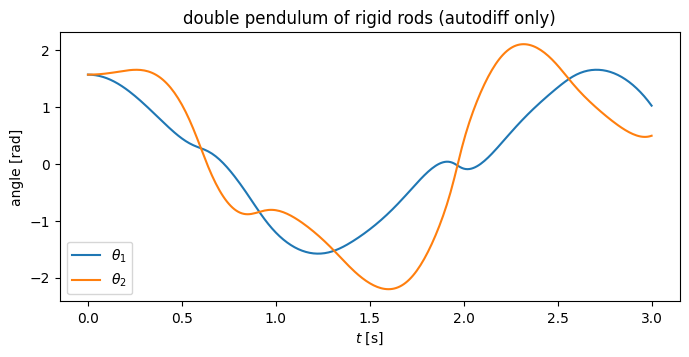

In [40]:
def rod_kinematics(q, qd, l):
    """Centre-of-mass positions and velocities of a chain of uniform rods."""
    # joint velocities: cumulative sums over the last axis, as for the point-mass chain
    jvx = torch.cumsum(l * torch.cos(q) * qd, dim=-1)
    jvy = torch.cumsum(l * torch.sin(q) * qd, dim=-1)
    jy = -torch.cumsum(l * torch.cos(q), dim=-1)
    # velocity/position of the joint ABOVE rod k = cumulative sum minus the term of rod k itself
    prev_vx = jvx - l * torch.cos(q) * qd
    prev_vy = jvy - l * torch.sin(q) * qd
    prev_y = jy + l * torch.cos(q)
    # centre of mass: half-way along rod k
    vcx = prev_vx + 0.5 * l * torch.cos(q) * qd
    vcy = prev_vy + 0.5 * l * torch.sin(q) * qd
    ycm = prev_y - 0.5 * l * torch.cos(q)
    return vcx, vcy, ycm

def lagrangian_rods(q, qd, m, l, g):
    vcx, vcy, ycm = rod_kinematics(q, qd, l)
    T = 0.5 * torch.sum(m * (vcx**2 + vcy**2), dim=-1) + 0.5 * torch.sum(m * l**2 / 12 * qd**2, dim=-1)
    V = g * torch.sum(m * ycm, dim=-1)
    return T - V

def energy_rods(q, qd, m, l, g):
    vcx, vcy, ycm = rod_kinematics(q, qd, l)
    return (0.5 * torch.sum(m * (vcx**2 + vcy**2), dim=-1) + 0.5 * torch.sum(m * l**2 / 12 * qd**2, dim=-1)
            + g * torch.sum(m * ycm, dim=-1))

# 2) single rod: compare with the exact theta'' = -(3g/2l) sin(theta)
m1t, l1t = torch.tensor([1.0]), torch.tensor([0.7])
L1 = lambda q, qd: lagrangian_rods(q, qd, m1t, l1t, 9.81)
rng = np.random.default_rng(2)
err = 0.0
for _ in range(20):
    th, om = rng.uniform(-np.pi, np.pi), rng.uniform(-5, 5)
    a = accel_from_lagrangian(L1, torch.tensor([th]), torch.tensor([om])).item()
    err = max(err, abs(a - (-1.5 * 9.81 / 0.7 * np.sin(th))))
print(f"single rod: max |autodiff - exact| = {err:.1e}")

# 3) double rod pendulum with autodiff accelerations only
m2t, l2t = torch.ones(2), torch.ones(2)
L2 = lambda q, qd: lagrangian_rods(q, qd, m2t, l2t, 9.81)
def accel_rods(q, w):
    # one state of shape (N,) -> a batch of one, shape (1, N), for accel_batch, and back
    return accel_batch(L2, torch.tensor(q)[None], torch.tensor(w)[None])[0].numpy()

t0 = time.perf_counter()
t_arr, Q, W = simulate(accel_rods, [np.pi / 2, np.pi / 2], [0.0, 0.0], T=3.0, dt=1e-2)
E = energy_rods(torch.tensor(Q), torch.tensor(W), m2t, l2t, 9.81).numpy()       # all time steps at once (batch)
print(f"simulated in {time.perf_counter() - t0:.0f} s;  max |E(t) - E(0)| = {np.max(np.abs(E - E[0])):.1e}  (E(0) = {E[0]:.3f})")
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.plot(t_arr, Q[:, 0], label=r"$\theta_1$"); ax.plot(t_arr, Q[:, 1], label=r"$\theta_2$")
ax.set_xlabel("$t$ [s]"); ax.set_ylabel("angle [rad]"); ax.legend(); ax.set_title("double pendulum of rigid rods (autodiff only)")
plt.show()